# AAPL Next-Day Return Forecasting: A Data Analytics × Machine Learning Project
**Author:** Malaika Junaid (202320048)

---
## Project overview
This notebook is an end-to-end, leakage-safe analytics and machine-learning study of Apple Inc. (AAPL) daily market data, 2014–2024.

**Research questions**
1. **RQ1 Data/analytics:** What are the statistical properties of AAPL returns (stationarity, fat tails, volatility clustering, seasonality)?
2. **RQ2 Machine learning:** Can regularised-linear and tree-ensemble models predict the *next-day return* (regression) and its *direction* (classification) better than naive baselines, out-of-sample?
3. **RQ3 Economics:** If there is a signal, does it survive transaction costs in a simple long/cash strategy?

**Design principles**
* **Target = next-day log return**, not the price level. Prices are non-stationary and a model can look excellent simply by copying yesterday's price; returns are stationary and are the honest target. Price forecasts are reconstructed from predicted returns and compared against the naive "tomorrow = today" benchmark.
* **No look-ahead:** every feature uses information up to the close of day *t* only; the target is day *t+1*. A programmatic **truncation test** proves this.
* **Time-aware validation:** expanding-window walk-forward cross-validation for tuning + a final untouched chronological hold-out set.
* **Honest evaluation:** out-of-sample R² vs the zero-return benchmark, Diebold–Mariano test, binomial test on directional accuracy, and a cost-aware backtest.

**Contents**
1. Setup & configuration · 2. Data ingestion · 3. Data quality & cleaning · 4. Exploratory data analysis · 5. Feature engineering · 6. Train/test design & feature analysis · 7. Regression modelling · 8. Direction classification · 9. Hold-out evaluation · 10. Explainability · 11. Strategy backtest · 12. Robustness · 13. Deployment artifacts · 14. Conclusions

## 1. Setup & configuration

In [1]:
import importlib.util, subprocess, sys
for _pkg in ['yfinance', 'xgboost']:
    if importlib.util.find_spec(_pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', _pkg])

import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
from scipy.stats import loguniform, uniform, randint
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import STL
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.linear_model import Ridge, ElasticNet, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (mean_squared_error, mean_absolute_error, accuracy_score, balanced_accuracy_score,
                             roc_auc_score, f1_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')

CFG = dict(
    TICKER='AAPL', START='2014-12-19', END='2024-09-16',
    SEED=42,
    TEST_FRAC=0.20,     # final chronological hold-out
    N_SPLITS=5,         # walk-forward CV folds
    GAP=1,              # rows purged between train and validation/test (label-overlap guard)
    N_ITER=15,          # random-search iterations for tree models
    COST_BPS=5,         # one-way transaction cost in basis points for the backtest
    ANN=252,            # trading days per year
)
SEED = CFG['SEED']
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
os.makedirs('data', exist_ok=True)
os.makedirs('artifacts', exist_ok=True)
print('Configuration:', json.dumps(CFG, indent=2))

Configuration: {
  "TICKER": "AAPL",
  "START": "2014-12-19",
  "END": "2024-09-16",
  "SEED": 42,
  "TEST_FRAC": 0.2,
  "N_SPLITS": 5,
  "GAP": 1,
  "N_ITER": 15,
  "COST_BPS": 5,
  "ANN": 252
}


## 2. Data ingestion
Daily OHLCV data is pulled from Yahoo Finance and cached to `data/` so the notebook still runs if the API is temporarily unavailable.

In [2]:
import yfinance as yf

cache_path = f"data/{CFG['TICKER']}_raw.csv"
try:
    raw = yf.download(CFG['TICKER'], start=CFG['START'], end=CFG['END'], auto_adjust=False, progress=False)
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    if raw.empty:
        raise ValueError('Yahoo Finance returned no rows')
    raw = raw.rename_axis('Date')
    raw.to_csv(cache_path)
    print(f'Downloaded {len(raw):,} rows from Yahoo Finance and cached to {cache_path}')
except Exception as e:
    if os.path.exists(cache_path):
        raw = pd.read_csv(cache_path, index_col=0, parse_dates=True)
        print(f'Download failed ({e}); loaded cached copy: {len(raw):,} rows')
    else:
        raise
display(raw.head())

Downloaded 2,449 rows from Yahoo Finance and cached to data/AAPL_raw.csv


Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2014-12-19,24.694660,27.945000,28.309999,27.915001,28.065001,353719200
2014-12-22,24.950933,28.235001,28.372499,27.992500,28.040001,180670000
2014-12-23,24.862570,28.135000,28.332500,28.115000,28.307501,104113600
2014-12-24,24.745474,28.002501,28.177500,28.002501,28.145000,57918400
2014-12-26,25.182898,28.497499,28.629999,28.002501,28.025000,134884000


## 3. Data quality & cleaning
**Adjustment:** raw `Close` is split-adjusted but not dividend-adjusted. We rebuild a *total-return* price series by scaling Open/High/Low with the `Adj Close / Close` factor, so that returns include dividends and are consistent across the OHLC columns.

In [3]:
df = raw[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']].copy()
df.index = pd.to_datetime(df.index)
df = df[~df.index.duplicated(keep='first')].sort_index()

adj_factor = df['Adj Close'] / df['Close']
for c in ['Open', 'High', 'Low']:
    df[c] = df[c] * adj_factor
df['Close'] = df['Adj Close']
df = df.drop(columns='Adj Close')

ohlc_bad = ((df['High'] < df[['Open', 'Close']].max(axis=1) * (1 - 1e-6)) |
            (df['Low'] > df[['Open', 'Close']].min(axis=1) * (1 + 1e-6)))

quality = pd.Series({
    'Rows': len(df),
    'Date range': f"{df.index.min().date()} -> {df.index.max().date()}",
    'Missing values': int(df.isna().sum().sum()),
    'Duplicate dates (raw)': int(raw.index.duplicated().sum()),
    'Zero-volume days': int((df['Volume'] == 0).sum()),
    'Non-positive prices': int((df[['Open', 'High', 'Low', 'Close']] <= 0).sum().sum()),
    'Inconsistent OHLC rows': int(ohlc_bad.sum()),
    'Calendar gaps > 4 days': int((df.index.to_series().diff().dt.days > 4).sum()),
}, name='Data-quality report')
display(quality.to_frame())

# Repair OHLC inconsistencies (if any) and forward-fill isolated missing values
df['High'] = df[['Open', 'High', 'Low', 'Close']].max(axis=1)
df['Low'] = df[['Open', 'High', 'Low', 'Close']].min(axis=1)
df = df.ffill().dropna()
df['ret'] = np.log(df['Close']).diff()          # daily log return (total return)

z = (df['ret'] - df['ret'].mean()) / df['ret'].std()
outliers = df.loc[z.abs() > 4, ['Close', 'ret']].assign(z_score=z[z.abs() > 4]).sort_values('z_score', key=abs, ascending=False)
print(f'\nExtreme-return days (|z| > 4): {len(outliers)} — kept, because they are genuine market events (e.g. Mar-2020), not errors.')
display(outliers.head(8))
display(df.describe().T)

,Data-quality report
Rows,2449
Date range,2014-12-19 -> 2024-09-13
Missing values,0
Duplicate dates (raw),0
Zero-volume days,0
Non-positive prices,0
Inconsistent OHLC rows,0
Calendar gaps > 4 days,0



Extreme-return days (|z| > 4): 11 — kept, because they are genuine market events (e.g. Mar-2020), not errors.


Price,Close,ret,z_score
Date,,,
2020-03-16,58.375599,-0.137708,-7.672513
2020-03-13,66.994202,0.113157,6.214469
2019-01-03,33.682335,-0.104924,-5.857716
2020-03-12,59.826496,-0.103978,-5.805336
2020-07-31,102.717194,0.099563,5.461958
2020-03-24,59.501129,0.095606,5.242880
2020-03-02,72.016884,0.089018,4.878207
2020-09-03,117.060425,-0.083448,-4.668862


,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
Open,2449.0,8.899366e+01,6.137174e+01,2.045527e+01,3.376518e+01,5.831293e+01,1.455416e+02,2.340692e+02
High,2449.0,8.995197e+01,6.202708e+01,2.083483e+01,3.401996e+01,5.921674e+01,1.473544e+02,2.348116e+02
Low,2449.0,8.809093e+01,6.075302e+01,2.033482e+01,3.357291e+01,5.745735e+01,1.443239e+02,2.307138e+02
Close,2449.0,8.906283e+01,6.141956e+01,2.053255e+01,3.378835e+01,5.832196e+01,1.457560e+02,2.324262e+02
Volume,2449.0,1.193131e+08,6.814917e+07,2.404830e+07,7.406430e+07,1.023556e+08,1.441144e+08,6.488252e+08
ret,2448.0,8.943015e-04,1.806480e-02,-1.377081e-01,-7.480328e-03,8.946598e-04,1.009697e-02,1.131574e-01


## 4. Exploratory data analysis (EDA)
### 4.1 Price, volume and drawdown

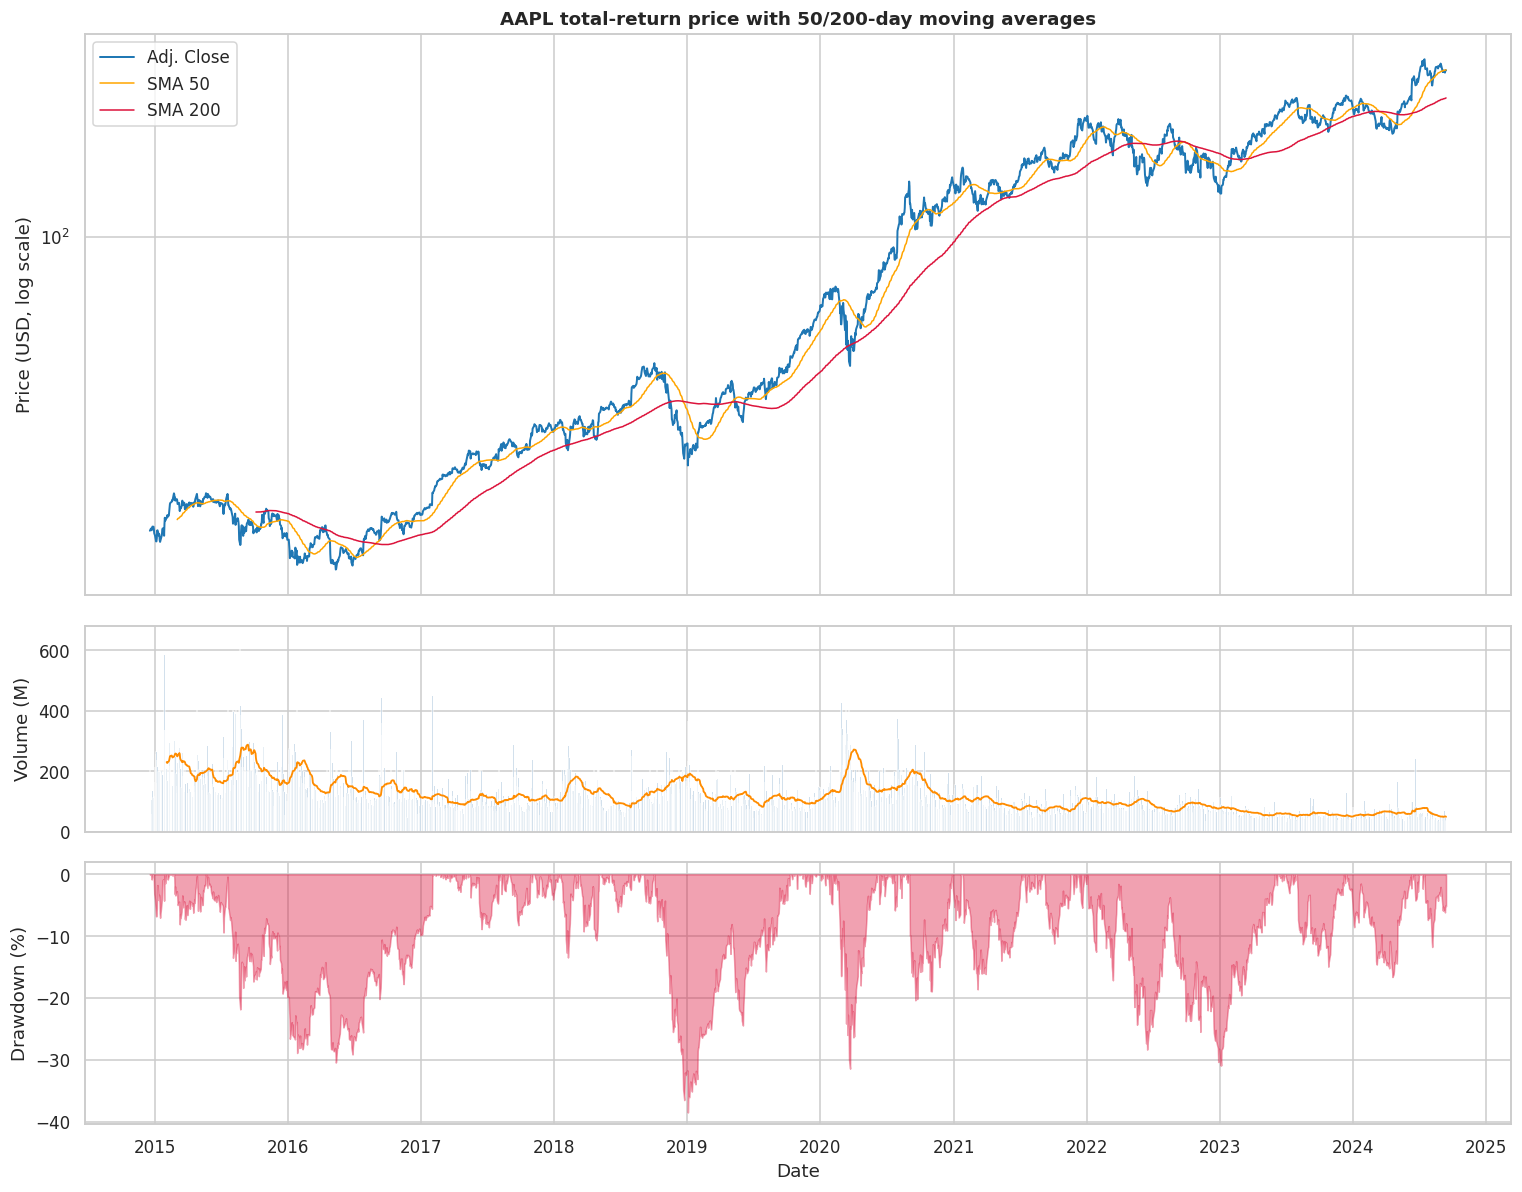

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(14, 11), sharex=True, gridspec_kw={'height_ratios': [3, 1.1, 1.4]})
ax[0].plot(df['Close'], color='#1f77b4', lw=1.3, label='Adj. Close')
ax[0].plot(df['Close'].rolling(50).mean(), color='orange', lw=1, label='SMA 50')
ax[0].plot(df['Close'].rolling(200).mean(), color='crimson', lw=1, label='SMA 200')
ax[0].set_yscale('log'); ax[0].set_ylabel('Price (USD, log scale)')
ax[0].set_title(f"{CFG['TICKER']} total-return price with 50/200-day moving averages"); ax[0].legend(loc='upper left')
ax[1].bar(df.index, df['Volume'] / 1e6, width=1.0, color='steelblue', alpha=0.6)
ax[1].plot(df['Volume'].rolling(30).mean() / 1e6, color='darkorange', lw=1.2)
ax[1].set_ylabel('Volume (M)')
drawdown = df['Close'] / df['Close'].cummax() - 1
ax[2].fill_between(df.index, drawdown * 100, 0, color='crimson', alpha=0.4)
ax[2].set_ylabel('Drawdown (%)'); ax[2].set_xlabel('Date')
plt.tight_layout(); plt.show()

### 4.2 Return distribution. Are returns normal?

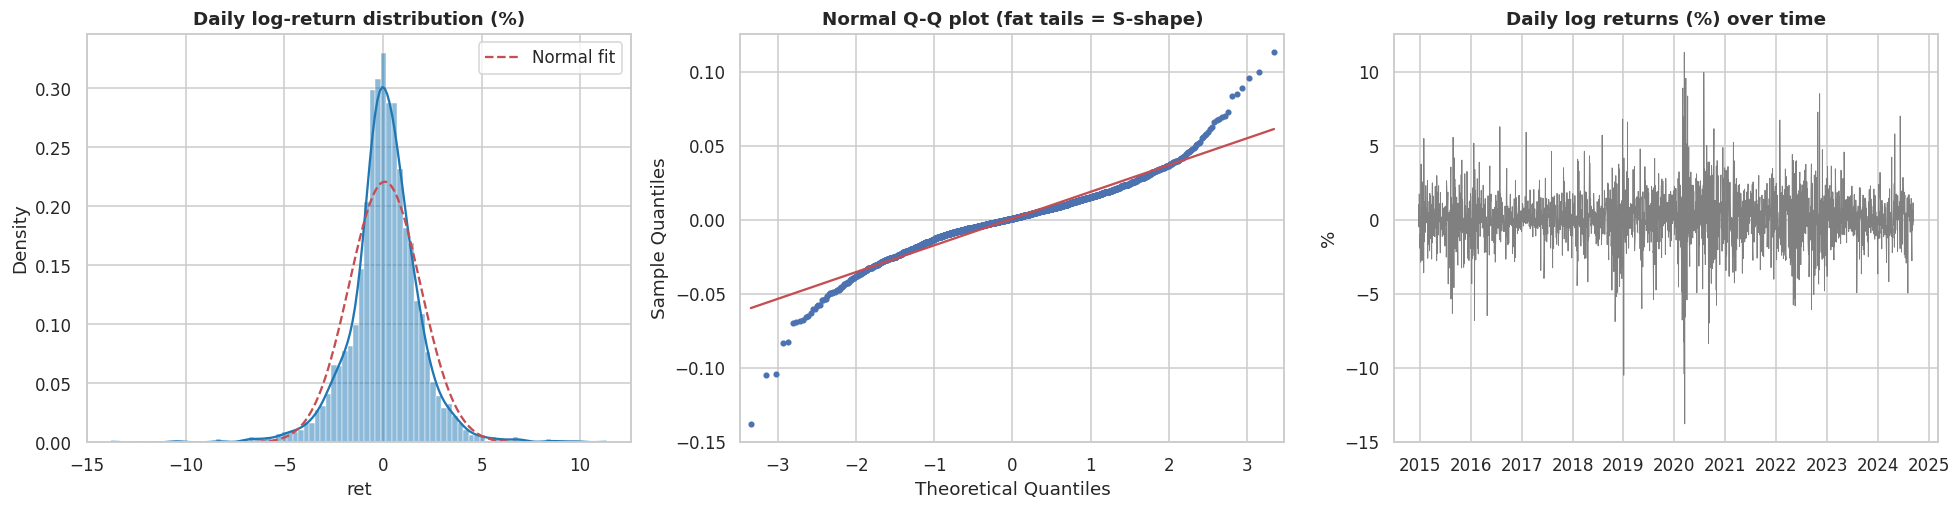

,AAPL daily returns
Mean daily return (%),0.0894
Std daily return (%),1.8065
Annualised return (%),22.5364
Annualised volatility (%),28.6770
Skewness,-0.1957
Excess kurtosis,5.4029
Jarque-Bera p-value,0.0000
Worst day (%),-13.7708
Best day (%),11.3157
% up days,52.9412


In [5]:
r = df['ret'].dropna()
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
sns.histplot(r * 100, bins=90, stat='density', kde=True, ax=ax[0], color='#1f77b4')
xs = np.linspace((r * 100).min(), (r * 100).max(), 400)
ax[0].plot(xs, stats.norm.pdf(xs, (r * 100).mean(), (r * 100).std()), 'r--', label='Normal fit')
ax[0].set_title('Daily log-return distribution (%)'); ax[0].legend()
sm.qqplot(r, line='s', ax=ax[1], markersize=3); ax[1].set_title('Normal Q-Q plot (fat tails = S-shape)')
ax[2].plot(r * 100, lw=0.6, color='gray'); ax[2].set_title('Daily log returns (%) over time'); ax[2].set_ylabel('%')
plt.tight_layout(); plt.show()

jb_stat, jb_p = stats.jarque_bera(r)
moments = pd.Series({
    'Mean daily return (%)': r.mean() * 100, 'Std daily return (%)': r.std() * 100,
    'Annualised return (%)': r.mean() * CFG['ANN'] * 100, 'Annualised volatility (%)': r.std() * np.sqrt(CFG['ANN']) * 100,
    'Skewness': stats.skew(r), 'Excess kurtosis': stats.kurtosis(r), 'Jarque-Bera p-value': jb_p,
    'Worst day (%)': r.min() * 100, 'Best day (%)': r.max() * 100, '% up days': (r > 0).mean() * 100,
}).round(4)
display(moments.to_frame('AAPL daily returns'))

### 4.3 Stationarity tests (why we model returns, not prices)
ADF: H0 = unit root (non-stationary). KPSS: H0 = stationary. A series is convincingly stationary when ADF rejects **and** KPSS does not.

In [6]:
def stationarity_row(s, name):
    s = s.dropna()
    adf_p = adfuller(s, autolag='AIC')[1]
    kpss_p = kpss(s, regression='c', nlags='auto')[1]
    return {'Series': name, 'ADF p-value': adf_p, 'KPSS p-value': kpss_p,
            'Verdict': 'Stationary' if (adf_p < 0.05 and kpss_p >= 0.05) else 'Non-stationary / inconclusive'}

stat_tbl = pd.DataFrame([
    stationarity_row(df['Close'], 'Price'),
    stationarity_row(np.log(df['Close']), 'Log price'),
    stationarity_row(df['ret'], 'Log return'),
    stationarity_row(df['ret'].abs(), '|Log return| (volatility proxy)'),
]).set_index('Series')
display(stat_tbl.style.format({'ADF p-value': '{:.4f}', 'KPSS p-value': '{:.4f}'}))

,ADF p-value,KPSS p-value,Verdict
Series,,,
Price,0.9813,0.0100,Non-stationary / inconclusive
Log price,0.9098,0.0100,Non-stationary / inconclusive
Log return,0.0000,0.1000,Stationary
|Log return| (volatility proxy),0.0000,0.0235,Non-stationary / inconclusive


### 4.4 Autocorrelation. is there linear predictability, and is there volatility clustering?
Returns themselves should be nearly uncorrelated (weak-form efficiency), whereas **squared/absolute returns** are strongly autocorrelated (volatility clustering, the ARCH effect).

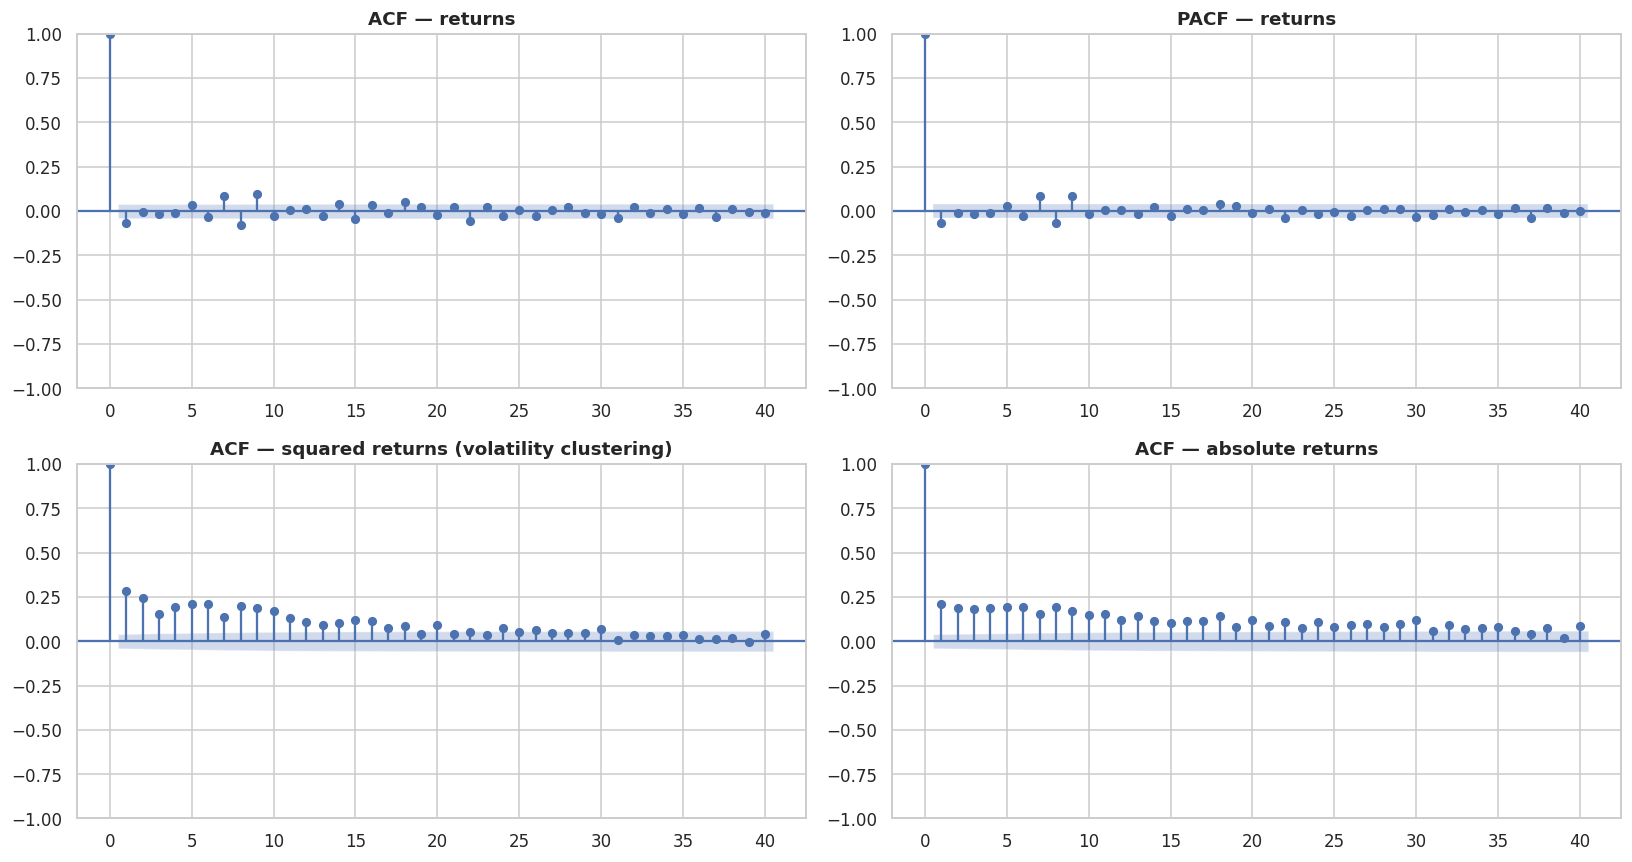

lb_stat  lb_pvalue
Returns         10    75.0105        0.0
                20    98.7271        0.0
Squared returns 10  1006.0666        0.0
                20  1246.1991        0.0

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
plot_acf(r, lags=40, ax=ax[0, 0], title='ACF — returns'); plot_pacf(r, lags=40, ax=ax[0, 1], title='PACF — returns', method='ywm')
plot_acf(r ** 2, lags=40, ax=ax[1, 0], title='ACF — squared returns (volatility clustering)')
plot_acf(r.abs(), lags=40, ax=ax[1, 1], title='ACF — absolute returns')
plt.tight_layout(); plt.show()

lb_ret = acorr_ljungbox(r, lags=[10, 20], return_df=True)
lb_sq = acorr_ljungbox(r ** 2, lags=[10, 20], return_df=True)
display(pd.concat({'Returns': lb_ret, 'Squared returns': lb_sq}, axis=0).round(4))

### 4.5 Volatility regimes and trend/seasonality decomposition

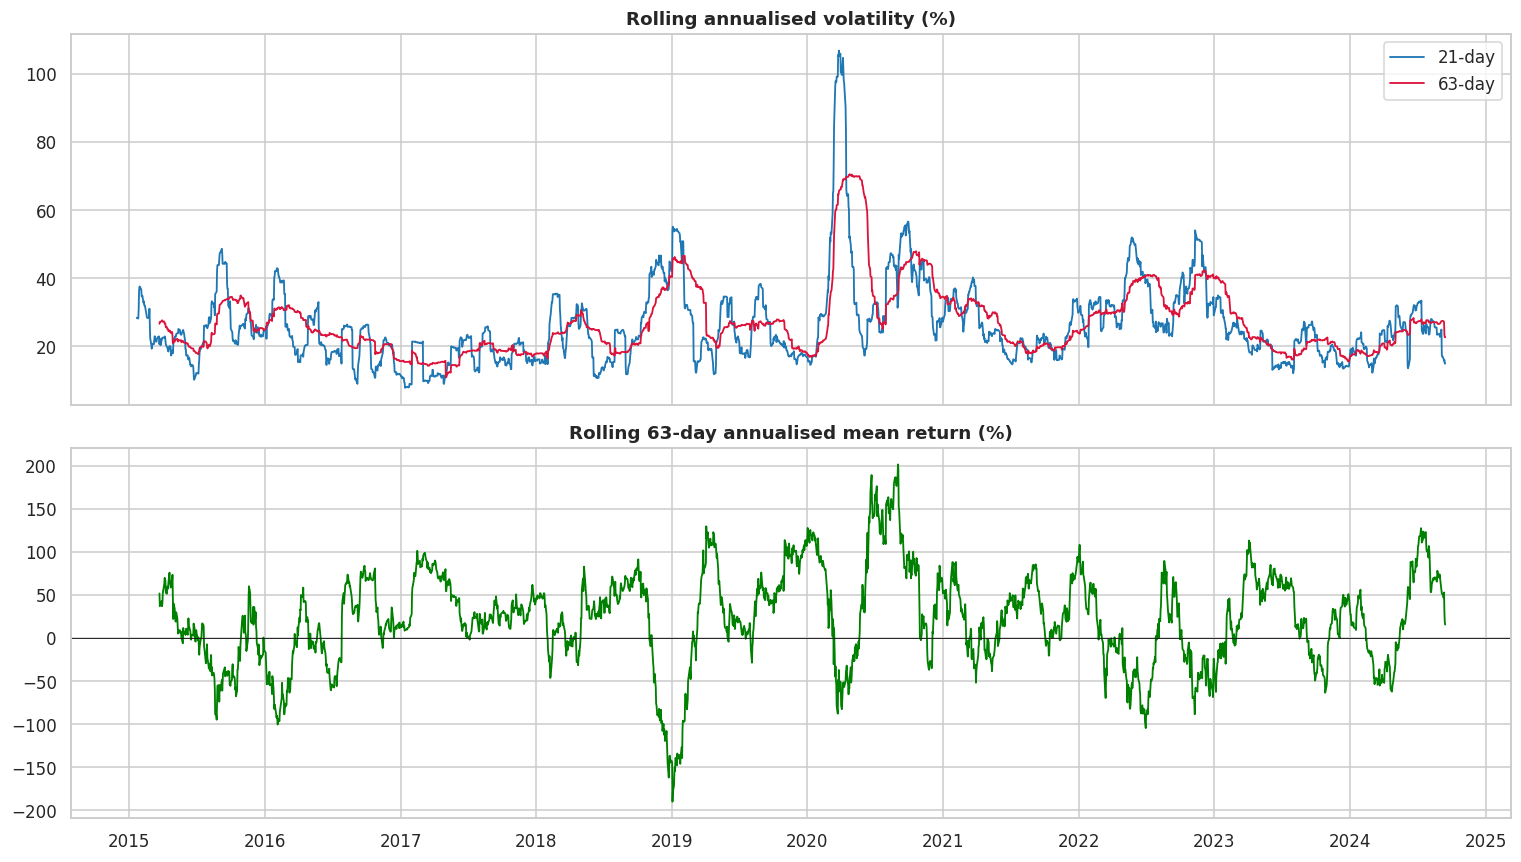

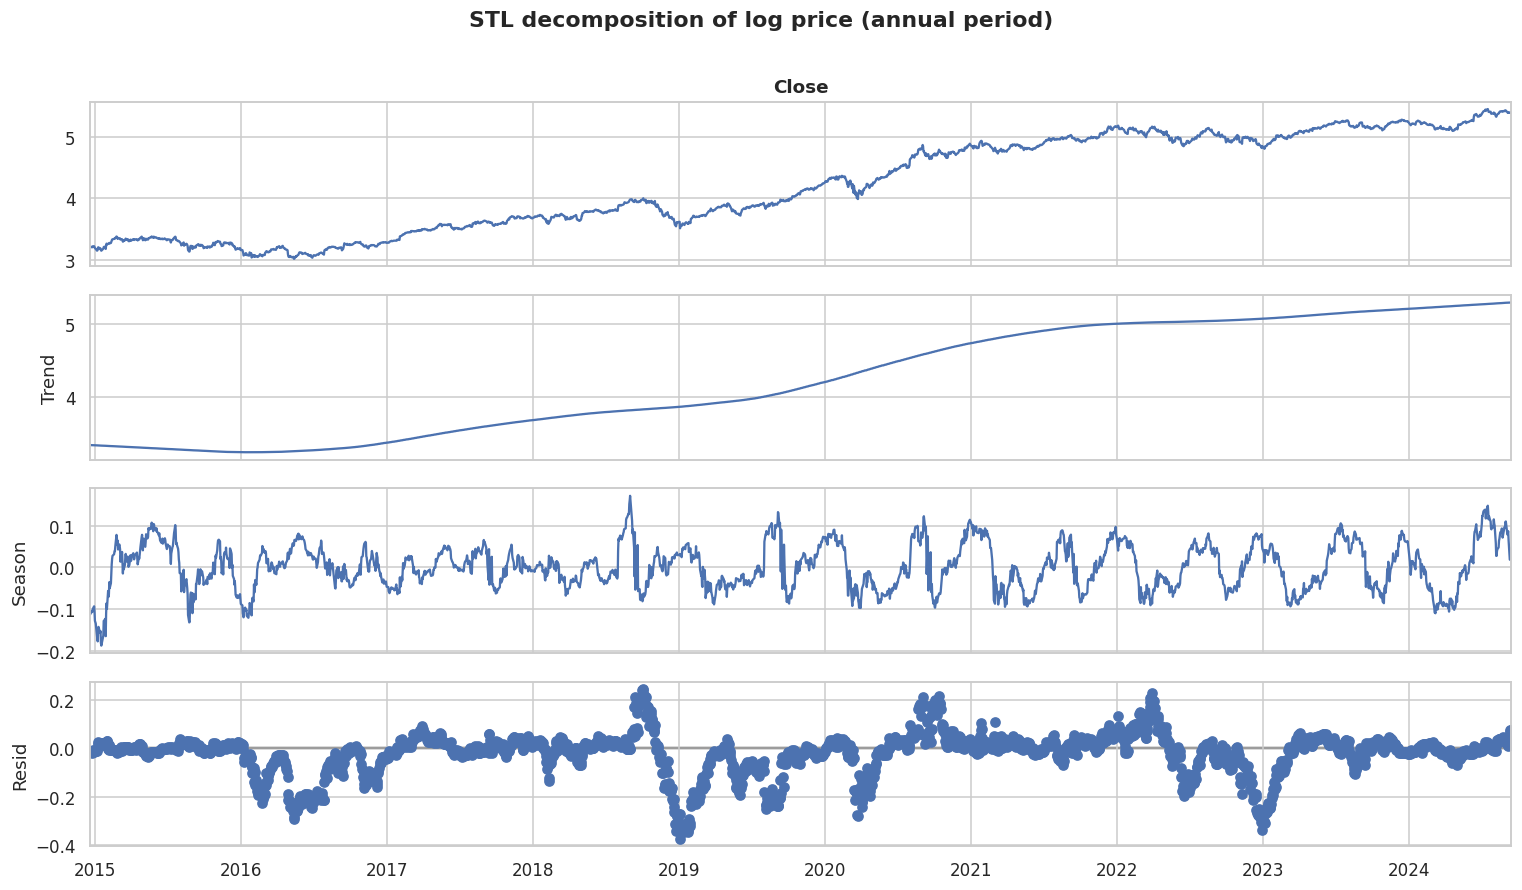

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for w, c in [(21, '#1f77b4'), (63, 'crimson')]:
    ax[0].plot(r.rolling(w).std() * np.sqrt(CFG['ANN']) * 100, label=f'{w}-day', color=c, lw=1.2)
ax[0].set_title('Rolling annualised volatility (%)'); ax[0].legend()
ax[1].plot(r.rolling(63).mean() * CFG['ANN'] * 100, color='green', lw=1.2); ax[1].axhline(0, color='k', lw=0.6)
ax[1].set_title('Rolling 63-day annualised mean return (%)')
plt.tight_layout(); plt.show()

stl = STL(np.log(df['Close']), period=CFG['ANN'], robust=True).fit()
fig = stl.plot(); fig.set_size_inches(14, 8); fig.suptitle('STL decomposition of log price (annual period)', y=1.01, fontweight='bold')
plt.tight_layout(); plt.show()

### 4.6 Calendar effects (day-of-week and month)
Bars show the mean return with a 95% confidence interval, if the interval spans zero, the "effect" is indistinguishable from noise.

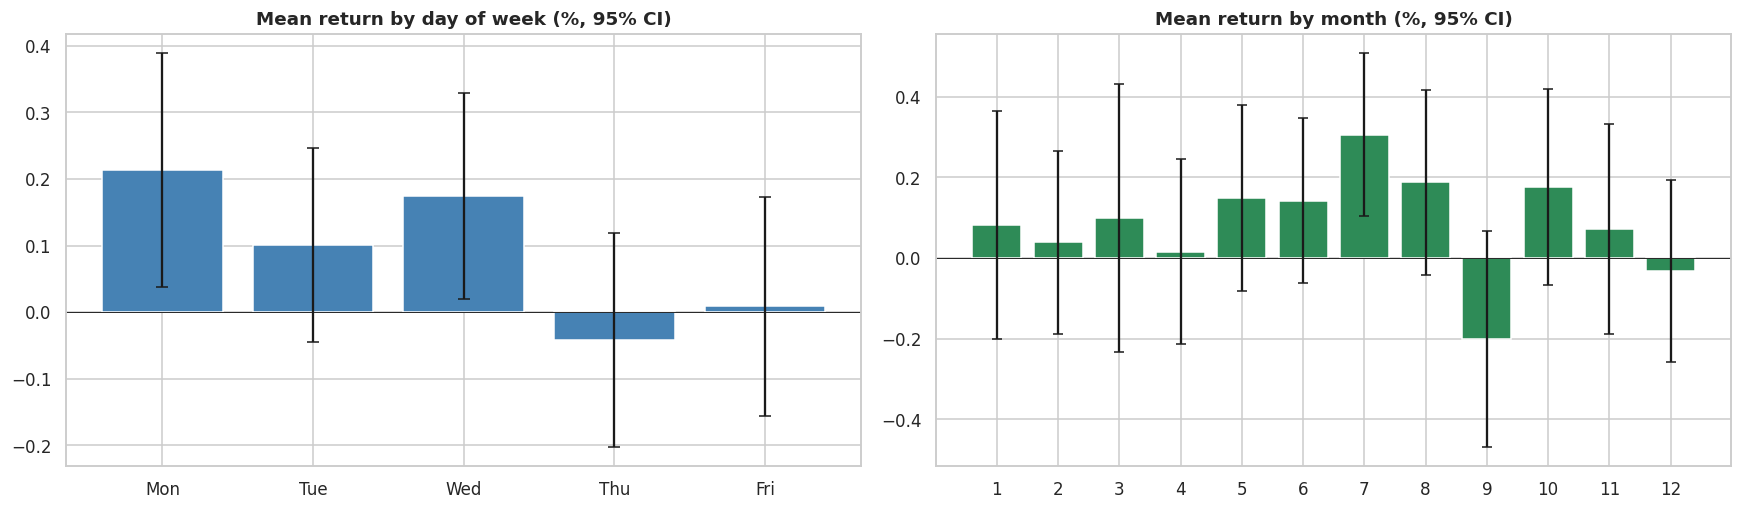

Kruskal-Wallis (day-of-week): p = 0.0292 | (month): p = 0.2444


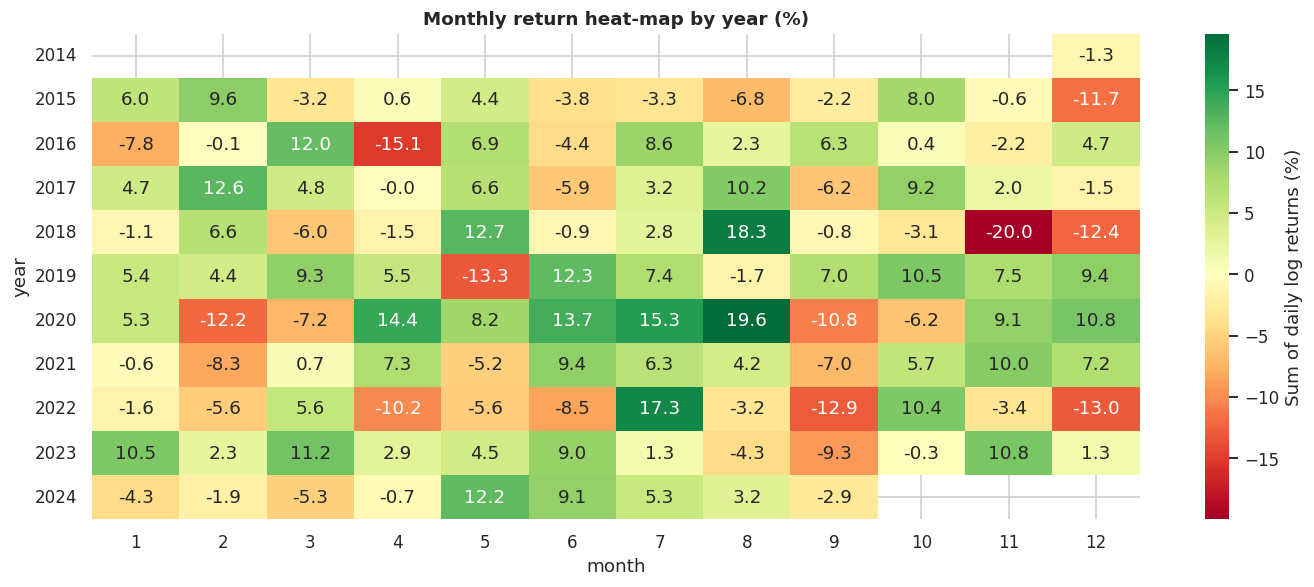

In [9]:
cal = pd.DataFrame({'ret': r * 100, 'dow': r.index.dayofweek, 'month': r.index.month, 'year': r.index.year})
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri']
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
g = cal.groupby('dow')['ret'].agg(['mean', 'sem'])
ax[0].bar(dow_names, g['mean'], yerr=1.96 * g['sem'], color='steelblue', capsize=4); ax[0].axhline(0, color='k', lw=0.6)
ax[0].set_title('Mean return by day of week (%, 95% CI)')
g2 = cal.groupby('month')['ret'].agg(['mean', 'sem'])
ax[1].bar(g2.index, g2['mean'], yerr=1.96 * g2['sem'], color='seagreen', capsize=3); ax[1].axhline(0, color='k', lw=0.6)
ax[1].set_xticks(range(1, 13)); ax[1].set_title('Mean return by month (%, 95% CI)')
plt.tight_layout(); plt.show()

kw_dow = stats.kruskal(*[g_.values for _, g_ in cal.groupby('dow')['ret']])
kw_mon = stats.kruskal(*[g_.values for _, g_ in cal.groupby('month')['ret']])
print(f'Kruskal-Wallis (day-of-week): p = {kw_dow.pvalue:.4f} | (month): p = {kw_mon.pvalue:.4f}')

heat = cal.pivot_table(index='year', columns='month', values='ret', aggfunc='sum')
plt.figure(figsize=(13, 5.5))
sns.heatmap(heat, annot=True, fmt='.1f', cmap='RdYlGn', center=0, cbar_kws={'label': 'Sum of daily log returns (%)'})
plt.title('Monthly return heat-map by year (%)'); plt.tight_layout(); plt.show()

### 4.7 Volume-volatility relationship and key EDA findings

,Spearman correlation
"corr(|ret_t|, |ret_t+1|) [volatility persistence]",0.1268
"corr(ret_t, ret_t+1) [return autocorrelation]",-0.0105
"corr(volume change_t, |ret_t|)",0.3262
"corr(ret_t, |ret_t+1|) [leverage effect]",-0.0658


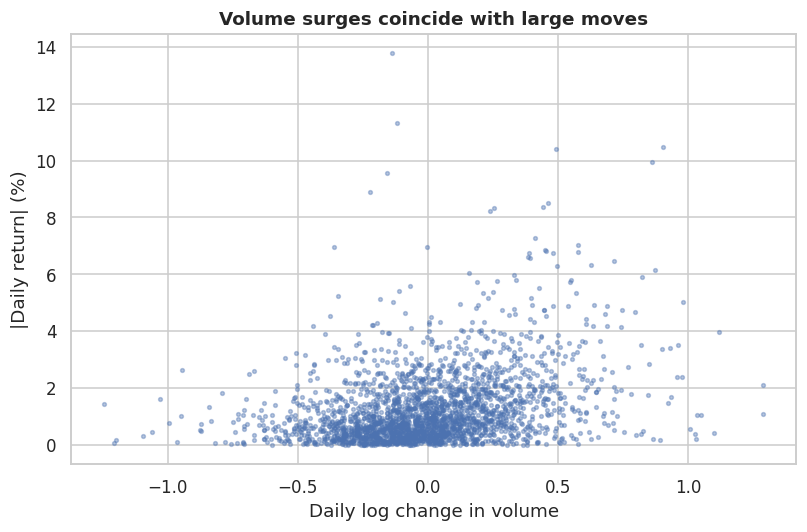


KEY EDA FINDINGS (computed from the data above)
  1. Returns are non-normal: excess kurtosis = 5.40, Jarque-Bera p = 0  -> fat tails.
  2. Price is non-stationary / inconclusive; returns are stationary  -> model returns.
  3. Return autocorrelation at lag 1 = -0.010 (tiny) vs volatility persistence = +0.127 -> volatility is far more predictable than direction.
  4. Calendar effects: Kruskal-Wallis p = 0.029 (day) / 0.244 (month); some evidence of seasonality.
  5. Max drawdown over the sample: -38.5%.


In [10]:
absr = df['ret'].abs()
vol_log_chg = np.log(df['Volume']).diff()
findings = {
    'corr(|ret_t|, |ret_t+1|)  [volatility persistence]': absr.corr(absr.shift(-1), method='spearman'),
    'corr(ret_t, ret_t+1)  [return autocorrelation]': df['ret'].corr(df['ret'].shift(-1), method='spearman'),
    'corr(volume change_t, |ret_t|)': vol_log_chg.corr(absr, method='spearman'),
    'corr(ret_t, |ret_t+1|)  [leverage effect]': df['ret'].corr(absr.shift(-1), method='spearman'),
}
display(pd.Series(findings, name='Spearman correlation').round(4).to_frame())

plt.figure(figsize=(7.5, 5))
plt.scatter(vol_log_chg, absr * 100, s=6, alpha=0.4)
plt.xlabel('Daily log change in volume'); plt.ylabel('|Daily return| (%)'); plt.title('Volume surges coincide with large moves')
plt.tight_layout(); plt.show()

print('\nKEY EDA FINDINGS (computed from the data above)')
print(f"  1. Returns are non-normal: excess kurtosis = {stats.kurtosis(r):.2f}, Jarque-Bera p = {jb_p:.2g}  -> fat tails.")
print(f"  2. Price is {stat_tbl.loc['Price', 'Verdict'].lower()}; returns are {stat_tbl.loc['Log return', 'Verdict'].lower()}  -> model returns.")
print(f"  3. Return autocorrelation at lag 1 = {findings['corr(ret_t, ret_t+1)  [return autocorrelation]']:+.3f} (tiny) vs volatility persistence = "
      f"{findings['corr(|ret_t|, |ret_t+1|)  [volatility persistence]']:+.3f} -> volatility is far more predictable than direction.")
print(f"  4. Calendar effects: Kruskal-Wallis p = {kw_dow.pvalue:.3f} (day) / {kw_mon.pvalue:.3f} (month); "
      f"{'some evidence of' if min(kw_dow.pvalue, kw_mon.pvalue) < 0.05 else 'no significant'} seasonality.")
print(f"  5. Max drawdown over the sample: {drawdown.min() * 100:.1f}%.")

## 5. Feature engineering
Features are grouped into families. **Everything is computed from data available at the close of day *t*; the target is the return of day *t+1*.**

| Family | Features |
|---|---|
| Return memory | `ret_1` (today's return), `ret_lag_1/2/3/5/10/20` |
| Momentum | cumulative log return over 5, 10, 21, 63 days |
| Volatility | rolling std (5/10/21/63), vol ratio, Parkinson range volatility, ATR, high–low range |
| Price action | overnight gap, intraday return, close location in the day's range |
| Trend | distance to SMA 5/10/20/50, MACD & histogram |
| Oscillators | RSI(14), Bollinger %B and bandwidth, Stochastic %K |
| Volume | log volume change, volume / 20-day average, 60-day volume z-score |
| Calendar | cyclical day-of-week & month encodings, month-end flag |

**Targets** (in % units, so model coefficients are on a comfortable scale): `target_ret = 100 × log(P_{t+1}/P_t)` for regression and `target_dir = 1[target_ret > 0]` for classification.

In [11]:
def rsi(close, n=14):
    delta = close.diff()
    up, down = delta.clip(lower=0), -delta.clip(upper=0)
    rs = up.ewm(alpha=1 / n, adjust=False, min_periods=n).mean() / down.ewm(alpha=1 / n, adjust=False, min_periods=n).mean()
    return 100 - 100 / (1 + rs)


def build_features(d):
    """Causal feature builder: row t uses only rows <= t."""
    f = pd.DataFrame(index=d.index)
    c, o, h, l, v = d['Close'], d['Open'], d['High'], d['Low'], d['Volume']
    lr = np.log(c).diff()

    f['ret_1'] = lr
    for k in [1, 2, 3, 5, 10, 20]:
        f[f'ret_lag_{k}'] = lr.shift(k)
    for k in [5, 10, 21, 63]:
        f[f'mom_{k}'] = np.log(c).diff(k)
    for k in [5, 10, 21, 63]:
        f[f'vol_{k}'] = lr.rolling(k).std()
    f['vol_ratio_5_21'] = f['vol_5'] / f['vol_21']
    f['parkinson_21'] = np.sqrt((np.log(h / l) ** 2).rolling(21).mean() / (4 * np.log(2)))
    f['hl_range'] = (h - l) / c
    f['gap'] = np.log(o / c.shift(1))
    f['intraday'] = np.log(c / o)
    f['close_loc'] = (c - l) / (h - l).replace(0, np.nan)
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
    f['atr_14'] = tr.ewm(alpha=1 / 14, adjust=False, min_periods=14).mean() / c
    for k in [5, 10, 20, 50]:
        f[f'dist_sma_{k}'] = c / c.rolling(k).mean() - 1
    macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
    f['macd'] = macd / c
    f['macd_hist'] = (macd - macd.ewm(span=9, adjust=False).mean()) / c
    f['rsi_14'] = rsi(c)
    m20, s20 = c.rolling(20).mean(), c.rolling(20).std()
    f['bb_pct_b'] = (c - (m20 - 2 * s20)) / (4 * s20)
    f['bb_width'] = 4 * s20 / m20
    ll, hh = l.rolling(14).min(), h.rolling(14).max()
    f['stoch_k'] = 100 * (c - ll) / (hh - ll)
    f['vol_chg'] = np.log(v.replace(0, np.nan)).diff()
    f['vol_rel_20'] = v / v.rolling(20).mean()
    f['vol_z_60'] = (v - v.rolling(60).mean()) / v.rolling(60).std()
    dow, mon = d.index.dayofweek, d.index.month
    f['dow_sin'], f['dow_cos'] = np.sin(2 * np.pi * dow / 5), np.cos(2 * np.pi * dow / 5)
    f['mon_sin'], f['mon_cos'] = np.sin(2 * np.pi * mon / 12), np.cos(2 * np.pi * mon / 12)
    f['is_month_end'] = d.index.is_month_end.astype(float)
    return f.replace([np.inf, -np.inf], np.nan)


# ---- Leakage guard: features at day t must be IDENTICAL whether or not the future exists --------
def lookahead_test(frame, cuts=(400, 900, 1500, 2100)):
    full = build_features(frame)
    for k in cuts:
        part = build_features(frame.iloc[:k])
        assert part.index[-1] == full.index[k - 1]
        assert np.allclose(part.iloc[-1].values.astype(float), full.iloc[k - 1].values.astype(float),
                           equal_nan=True, rtol=1e-8, atol=1e-10), f'Look-ahead detected at cut {k}!'
    print(f'Truncation test PASSED at cut points {cuts}: no feature uses future information.')

lookahead_test(df)

FEATS = build_features(df)
feature_cols = list(FEATS.columns)

data = FEATS.copy()
data['price'] = df['Close']
data['next_price'] = df['Close'].shift(-1)
data['target_ret'] = 100 * df['ret'].shift(-1)          # % log return of day t+1
data['target_dir'] = (data['target_ret'] > 0).astype(int)

live_row = FEATS.dropna().iloc[[-1]]                      # newest day: features known, target unknown (used for inference)
model_df = data.dropna(subset=feature_cols + ['target_ret'])
print(f'{len(feature_cols)} features | modelling rows: {len(model_df):,} | '
      f'rows lost to rolling windows/shift: {len(df) - len(model_df)}')
display(model_df[feature_cols + ['target_ret']].head(3).T.head(12))

Truncation test PASSED at cut points (400, 900, 1500, 2100): no feature uses future information.
40 features | modelling rows: 2,385 | rows lost to rolling windows/shift: 64


Date,2015-03-24,2015-03-25,2015-03-26
ret_1,-0.004096,-0.026474,0.006946
ret_lag_1,0.010351,-0.004096,-0.026474
ret_lag_2,-0.012628,0.010351,-0.004096
ret_lag_3,-0.007579,-0.012628,0.010351
ret_lag_5,0.016589,0.011193,-0.007579
ret_lag_10,-0.020903,-0.018400,0.017918
ret_lag_20,-0.006260,-0.025906,0.012577
mom_5,-0.002759,-0.040426,-0.025901
mom_10,0.017357,0.009283,-0.001689
mom_21,-0.048606,-0.068820,-0.035968


## 6. Train / test design & feature analysis
* **Hold-out test set:** the most recent 20% of days. It is **never** touched during tuning or feature analysis.
* **Purge gap:** the last training row's target is the first test day's return, so we drop `GAP` rows between train and test to prevent label overlap.
* **Walk-forward CV** (inside the training set only): an expanding window, each fold trains on the past and validates on the next block.

Train: 1,907 rows  (2015-03-24 -> 2022-10-17)
Test : 477 rows  (2022-10-19 -> 2024-09-12)
Share of up-days  train = 0.524 | test = 0.541


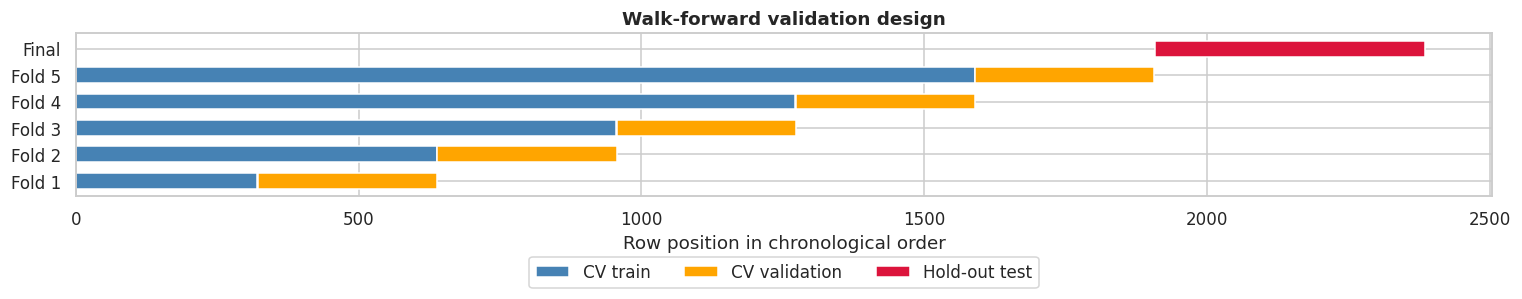

In [12]:
n = len(model_df)
n_test = int(n * CFG['TEST_FRAC'])
train = model_df.iloc[: n - n_test - CFG['GAP']]
test = model_df.iloc[n - n_test:]

X_train, y_train, yd_train = train[feature_cols], train['target_ret'], train['target_dir']
X_test, y_test, yd_test = test[feature_cols], test['target_ret'], test['target_dir']
tscv = TimeSeriesSplit(n_splits=CFG['N_SPLITS'], gap=CFG['GAP'])

print(f"Train: {len(train):,} rows  ({train.index.min().date()} -> {train.index.max().date()})")
print(f"Test : {len(test):,} rows  ({test.index.min().date()} -> {test.index.max().date()})")
print(f"Share of up-days  train = {yd_train.mean():.3f} | test = {yd_test.mean():.3f}")

fig, ax = plt.subplots(figsize=(14, 3.2))
for i, (tr_idx, va_idx) in enumerate(tscv.split(X_train)):
    ax.barh(i, len(tr_idx), left=0, color='steelblue', height=0.6, label='CV train' if i == 0 else None)
    ax.barh(i, len(va_idx), left=va_idx[0], color='orange', height=0.6, label='CV validation' if i == 0 else None)
ax.barh(CFG['N_SPLITS'], len(X_test), left=len(train) + CFG['GAP'], color='crimson', height=0.6, label='Hold-out test')
ax.set_yticks(range(CFG['N_SPLITS'] + 1)); ax.set_yticklabels([f'Fold {i + 1}' for i in range(CFG['N_SPLITS'])] + ['Final'])
ax.set_xlabel('Row position in chronological order'); ax.set_title('Walk-forward validation design')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.32))
plt.tight_layout(); plt.show()

### 6.1 Feature relationships (training data only)

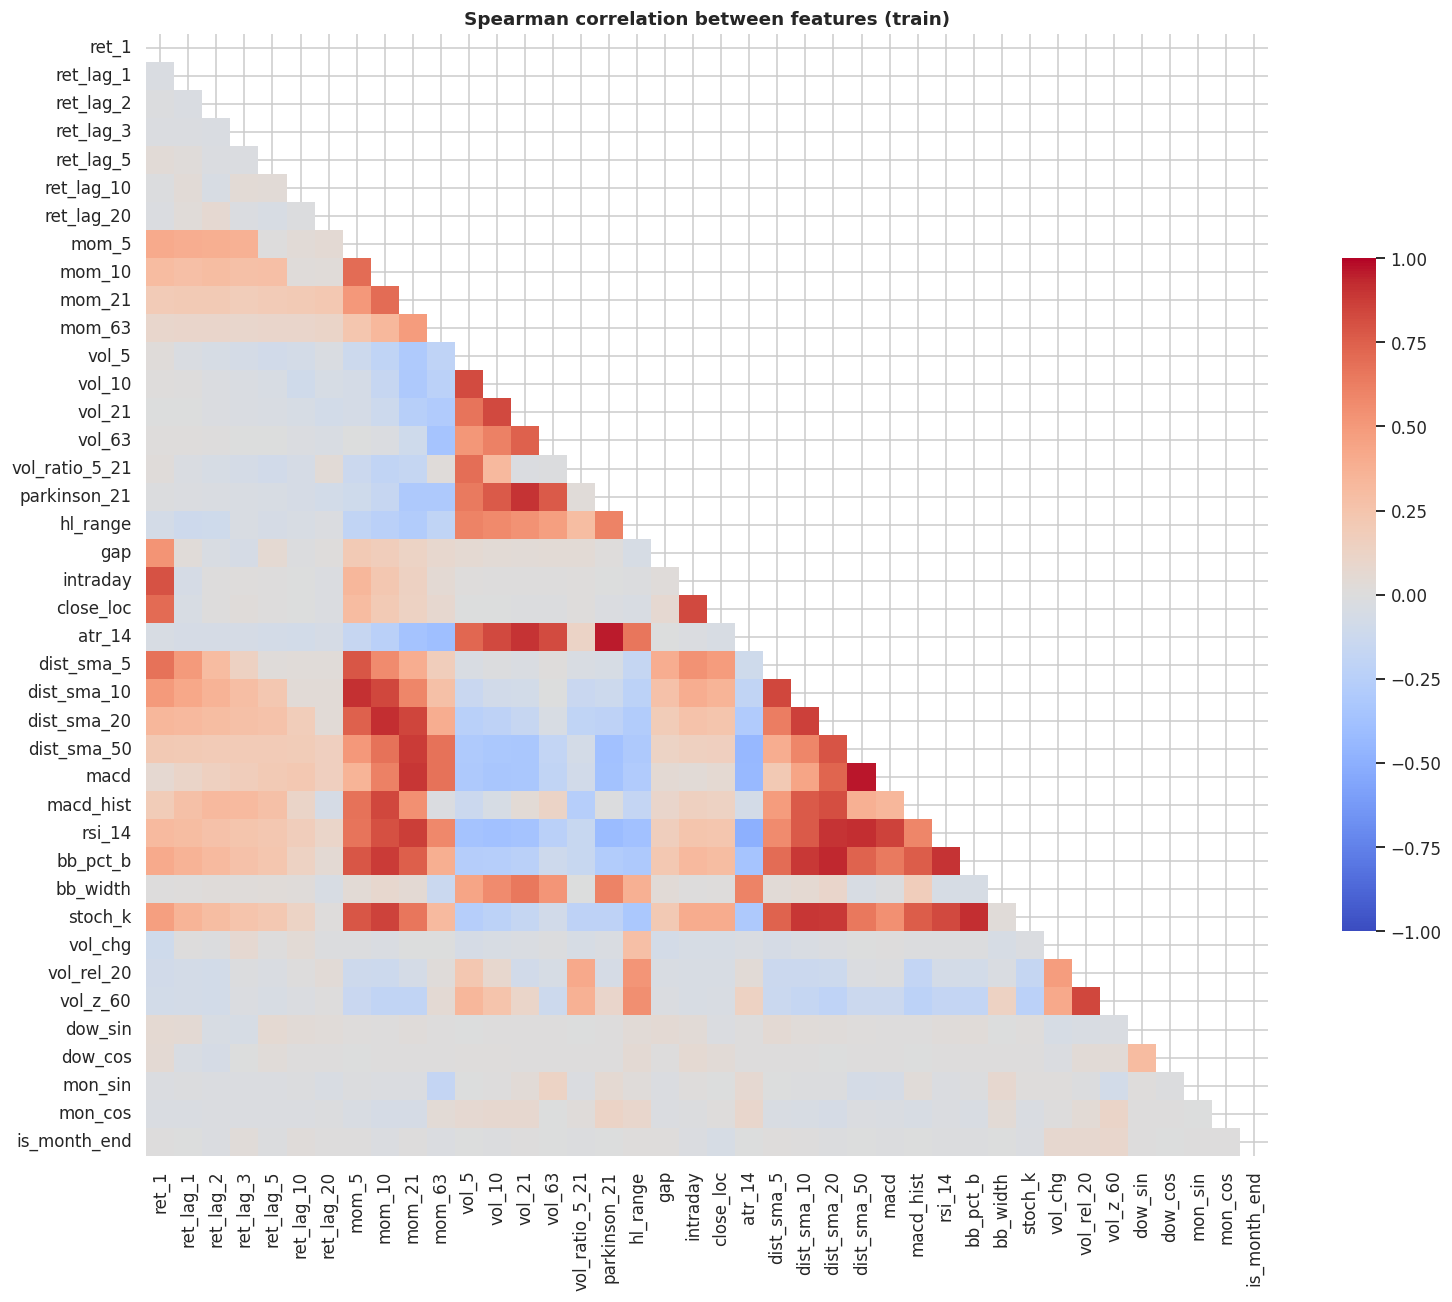

Most redundant feature pairs (|rho| > 0.9):


,feature_a,feature_b,rho
350,macd,dist_sma_50,0.966
226,atr_14,parkinson_21,0.954
430,bb_pct_b,dist_sma_20,0.932
494,stoch_k,bb_pct_b,0.920
284,dist_sma_20,mom_10,0.918
403,rsi_14,dist_sma_50,0.915
260,dist_sma_10,mom_5,0.909
402,rsi_14,dist_sma_20,0.905
434,bb_pct_b,rsi_14,0.901


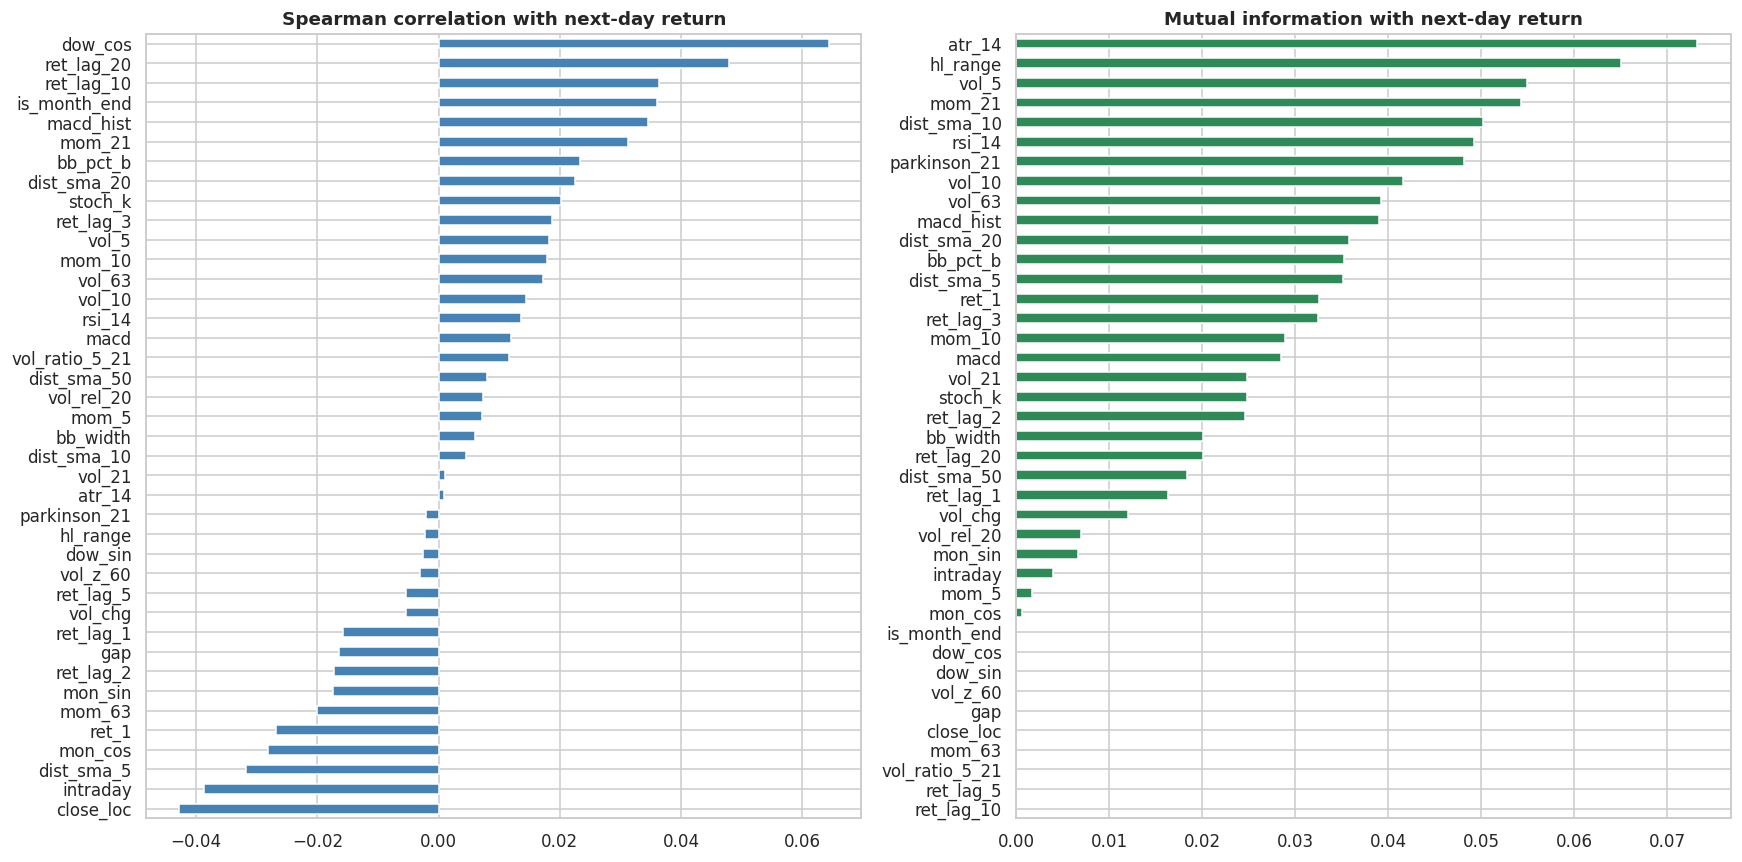

Strongest single-feature |Spearman| with next-day return: 0.064 (values this small are typical: daily returns are very hard to predict).


In [13]:
corr = X_train.corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(15, 12))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.6})
plt.title('Spearman correlation between features (train)'); plt.tight_layout(); plt.show()

pairs = corr.where(~mask).stack().rename('rho').reset_index()
pairs.columns = ['feature_a', 'feature_b', 'rho']
print('Most redundant feature pairs (|rho| > 0.9):')
display(pairs[pairs['rho'].abs() > 0.9].sort_values('rho', key=abs, ascending=False).head(10).round(3))

spearman_y = X_train.apply(lambda s: stats.spearmanr(s, y_train)[0])
mi = pd.Series(mutual_info_regression(X_train, y_train, random_state=SEED), index=feature_cols)
fi = pd.DataFrame({'Spearman vs target': spearman_y, 'Mutual information': mi})
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
fi['Spearman vs target'].sort_values().plot.barh(ax=ax[0], color='steelblue'); ax[0].set_title('Spearman correlation with next-day return')
fi['Mutual information'].sort_values().plot.barh(ax=ax[1], color='seagreen'); ax[1].set_title('Mutual information with next-day return')
plt.tight_layout(); plt.show()
print(f"Strongest single-feature |Spearman| with next-day return: {fi['Spearman vs target'].abs().max():.3f} "
      "(values this small are typical: daily returns are very hard to predict).")

## 7. Regression modelling, predicting the next-day return
### 7.1 Evaluation metrics & baselines
* **RMSE / MAE** (in % points of return).
* **R²\_OS** = 1 − SSE(model) / SSE(zero-return forecast). Positive ⇒ the model beats a random-walk forecast out-of-sample (Campbell–Thompson). Ordinary R² is misleading here because returns have near-zero mean.
* **Directional accuracy** — how often the sign of the forecast matches the sign of the realised return.

**Baselines:** (1) *random walk* — predict 0% (equivalently "tomorrow's price = today's price"); (2) *historical mean* return of the training set.

In [14]:
def r2_os(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum(y ** 2)

def reg_metrics(y, p, dir_hat=None):
    y, p = np.asarray(y), np.asarray(p)
    dir_hat = (p > 0) if dir_hat is None else dir_hat
    return {'RMSE': np.sqrt(mean_squared_error(y, p)), 'MAE': mean_absolute_error(y, p),
            'R2_OS': r2_os(y, p), 'DirAcc': np.mean(dir_hat == (y > 0))}

def baseline_cv(kind):
    rows = []
    for tr_i, va_i in tscv.split(X_train):
        yv = y_train.iloc[va_i].values
        p = np.zeros(len(yv)) if kind == 'zero' else np.full(len(yv), y_train.iloc[tr_i].mean())
        rows.append(np.sqrt(np.mean((yv - p) ** 2)))
    return np.mean(rows), np.std(rows)

### 7.2 Candidate models and hyper-parameter tuning
Four model families of increasing flexibility are tuned with **randomised search over walk-forward folds** (scoring = RMSE). Linear models are standardised inside a `Pipeline` so that scaling statistics are learned from each training fold only.
* **Ridge / Elastic Net** — regularised linear models; shrinkage handles the heavy multicollinearity found above.
* **Random Forest** — bagged trees; robust to noise, captures interactions.
* **Histogram Gradient Boosting** and **XGBoost** — boosted trees; strong on tabular data but prone to overfitting noisy targets, hence heavy regularisation in the search space.

In [15]:
def make_pipe(model, scale=True):
    return Pipeline([('scaler', StandardScaler() if scale else 'passthrough'), ('model', model)])

reg_specs = {
    'Ridge': (make_pipe(Ridge()), {'model__alpha': loguniform(1e-1, 1e5)}, 25),
    'ElasticNet': (make_pipe(ElasticNet(max_iter=20000)),
                   {'model__alpha': loguniform(1e-3, 10), 'model__l1_ratio': uniform(0.05, 0.9)}, 25),
    'Random Forest': (make_pipe(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1), scale=False),
                      {'model__max_depth': [3, 5, 8, 12], 'model__min_samples_leaf': [5, 10, 20, 40, 80],
                       'model__max_features': [0.2, 0.35, 0.5, 'sqrt']}, CFG['N_ITER']),
    'HistGradientBoosting': (make_pipe(HistGradientBoostingRegressor(random_state=SEED, early_stopping=False), scale=False),
                             {'model__learning_rate': loguniform(0.01, 0.2), 'model__max_depth': [2, 3, 4, 6],
                              'model__max_iter': [100, 200, 400], 'model__min_samples_leaf': [20, 40, 80],
                              'model__l2_regularization': loguniform(1e-3, 10)}, CFG['N_ITER']),
}
try:
    from xgboost import XGBRegressor
    reg_specs['XGBoost'] = (make_pipe(XGBRegressor(random_state=SEED, n_jobs=1, tree_method='hist', verbosity=0), scale=False),
                            {'model__n_estimators': [100, 200, 400], 'model__learning_rate': loguniform(0.01, 0.2),
                             'model__max_depth': [2, 3, 4, 5], 'model__subsample': uniform(0.6, 0.4),
                             'model__colsample_bytree': uniform(0.5, 0.5), 'model__min_child_weight': [1, 5, 10, 20],
                             'model__reg_lambda': loguniform(1e-2, 50)}, CFG['N_ITER'])
except ImportError:
    print('xgboost not installed — skipping XGBoost.')

reg_search = {}
for name, (pipe, dist, n_iter) in reg_specs.items():
    t0 = time.time()
    s = RandomizedSearchCV(pipe, dist, n_iter=n_iter, cv=tscv, scoring='neg_root_mean_squared_error',
                           random_state=SEED, n_jobs=-1, refit=True)
    s.fit(X_train, y_train)
    reg_search[name] = s
    print(f'{name:<22} CV RMSE = {-s.best_score_:.4f}  ({time.time() - t0:5.1f}s)  best params: '
          f"{ {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()} }")

Ridge                  CV RMSE = 1.8670  (  2.9s)  best params: {'alpha': np.float64(65987.1107)}
ElasticNet             CV RMSE = 1.8670  (  2.0s)  best params: {'alpha': np.float64(0.8472), 'l1_ratio': np.float64(0.5888)}
Random Forest          CV RMSE = 1.8705  (149.0s)  best params: {'min_samples_leaf': 40, 'max_features': 'sqrt', 'max_depth': 3}
HistGradientBoosting   CV RMSE = 1.8833  ( 21.8s)  best params: {'l2_regularization': np.float64(4.8696), 'learning_rate': np.float64(0.013), 'max_depth': 4, 'max_iter': 100, 'min_samples_leaf': 40}
XGBoost                CV RMSE = 1.9060  ( 27.6s)  best params: {'colsample_bytree': np.float64(0.9162), 'learning_rate': np.float64(0.0189), 'max_depth': 5, 'min_child_weight': 20, 'n_estimators': 100, 'reg_lambda': np.float64(1.9233), 'subsample': np.float64(0.8447)}


### 7.3 Cross-validated comparison (walk-forward, training period only)
Note that these CV scores are slightly optimistic for tuned models (the hyper-parameters were chosen on them). The **hold-out test in §9 is the unbiased verdict**.

In [16]:
cv_rows = []
for nm, kind in [('Random walk (0%)', 'zero'), ('Historical mean', 'mean')]:
    m, s_ = baseline_cv(kind); cv_rows.append({'Model': nm, 'CV RMSE': m, 'CV RMSE std (across folds)': s_})
for nm, s in reg_search.items():
    cv_rows.append({'Model': nm, 'CV RMSE': -s.best_score_, 'CV RMSE std (across folds)': s.cv_results_['std_test_score'][s.best_index_]})
cv_table = pd.DataFrame(cv_rows).set_index('Model').sort_values('CV RMSE')
display(cv_table.style.format('{:.4f}').background_gradient(subset=['CV RMSE'], cmap='Greens_r'))

champion_name = max(reg_search, key=lambda k: reg_search[k].best_score_)      # highest neg-RMSE = lowest RMSE
print(f'Champion regressor chosen by walk-forward CV (not by test data): {champion_name}')

,CV RMSE,CV RMSE std (across folds)
Model,,
Random walk (0%),1.8653,0.4066
Historical mean,1.8670,0.4008
ElasticNet,1.8670,0.4008
Ridge,1.8670,0.4003
Random Forest,1.8705,0.3898
HistGradientBoosting,1.8833,0.3843
XGBoost,1.9060,0.3747


Champion regressor chosen by walk-forward CV (not by test data): ElasticNet


## 8. Classification, predicting the direction of the next day
The same features are used to predict `target_dir` (1 = up). Baseline: always predict "up" (the majority class). We tune with walk-forward CV on **ROC-AUC** (0.5 = coin flip).

In [17]:
clf_specs = {
    'Logistic Regression': (make_pipe(LogisticRegression(max_iter=5000)), {'model__C': loguniform(1e-4, 1e1)}, 20),
    'Random Forest': (make_pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1), scale=False),
                      {'model__max_depth': [3, 5, 8, 12], 'model__min_samples_leaf': [5, 10, 20, 40, 80],
                       'model__max_features': [0.2, 0.35, 0.5, 'sqrt']}, CFG['N_ITER']),
    'HistGradientBoosting': (make_pipe(HistGradientBoostingClassifier(random_state=SEED, early_stopping=False), scale=False),
                             {'model__learning_rate': loguniform(0.01, 0.2), 'model__max_depth': [2, 3, 4, 6],
                              'model__max_iter': [100, 200, 400], 'model__min_samples_leaf': [20, 40, 80],
                              'model__l2_regularization': loguniform(1e-3, 10)}, CFG['N_ITER']),
}
clf_search = {}
for name, (pipe, dist, n_iter) in clf_specs.items():
    t0 = time.time()
    s = RandomizedSearchCV(pipe, dist, n_iter=n_iter, cv=tscv, scoring='roc_auc', random_state=SEED, n_jobs=-1, refit=True)
    s.fit(X_train, yd_train)
    clf_search[name] = s
    print(f'{name:<22} CV ROC-AUC = {s.best_score_:.4f}  ({time.time() - t0:5.1f}s)')
clf_champion_name = max(clf_search, key=lambda k: clf_search[k].best_score_)
print(f'Champion classifier (by CV AUC): {clf_champion_name}')

Logistic Regression    CV ROC-AUC = 0.5236  (  1.5s)
Random Forest          CV ROC-AUC = 0.5195  (129.3s)
HistGradientBoosting   CV ROC-AUC = 0.5274  ( 22.9s)
Champion classifier (by CV AUC): HistGradientBoosting


## 9. Hold-out evaluation (the unbiased test)
Every tuned model was already refit on the **full training set** by the search. We now score all models once on the untouched test period. Price-level metrics are obtained by converting each return forecast back to a price: `P̂_{t+1} = P_t · exp(r̂/100)`; the naive price benchmark is simply `P_t`.

In [18]:
yt = y_test.values
P_t, P_next = test['price'].values, test['next_price'].values

preds = {'Random walk (0%)': np.zeros(len(yt)), 'Historical mean': np.full(len(yt), y_train.mean())}
for nm, s in reg_search.items():
    preds[nm] = s.best_estimator_.predict(X_test)
ml_names = list(reg_search)
preds['Ensemble (mean of ML models)'] = np.mean([preds[nm] for nm in ml_names], axis=0)

rows = []
for nm, p in preds.items():
    dir_hat = np.ones(len(yt), dtype=bool) if nm == 'Random walk (0%)' else None       # RW has no view -> "always up"
    m = reg_metrics(yt, p, dir_hat)
    p_hat = P_t * np.exp(p / 100)
    m.update({'Price RMSE ($)': np.sqrt(np.mean((P_next - p_hat) ** 2)),
              'Price MAE ($)': np.mean(np.abs(P_next - p_hat)),
              'Price MAPE (%)': np.mean(np.abs(P_next - p_hat) / P_next) * 100})
    rows.append({'Model': nm, **m})
holdout_tbl = pd.DataFrame(rows).set_index('Model').sort_values('RMSE')
display(holdout_tbl.style.format({'RMSE': '{:.4f}', 'MAE': '{:.4f}', 'R2_OS': '{:+.4f}', 'DirAcc': '{:.3f}',
                                  'Price RMSE ($)': '{:.3f}', 'Price MAE ($)': '{:.3f}', 'Price MAPE (%)': '{:.3f}'})
        .background_gradient(subset=['RMSE'], cmap='Greens_r').background_gradient(subset=['R2_OS'], cmap='Greens'))

# ---- statistical significance ---------------------------------------------------------------
def diebold_mariano(y, p_base, p_model):
    """One-sided-informative DM test on squared-error loss; positive stat => model has LOWER loss than baseline."""
    d = (y - p_base) ** 2 - (y - p_model) ** 2
    stat = d.mean() / np.sqrt(d.var(ddof=1) / len(d))
    return stat, 2 * (1 - stats.norm.cdf(abs(stat)))

champ_pred = preds[champion_name]
dm_rows = []
for nm in [champion_name, 'Ensemble (mean of ML models)']:
    st, pv = diebold_mariano(yt, preds['Random walk (0%)'], preds[nm])
    k = int(np.sum((preds[nm] > 0) == (yt > 0))); base_rate = float(np.mean(yt > 0))
    bt = stats.binomtest(k, len(yt), base_rate, alternative='greater')
    dm_rows.append({'Model': nm, 'DM stat vs random walk': st, 'DM p-value (two-sided)': pv,
                    'Directional accuracy': k / len(yt), 'Always-up accuracy (test)': base_rate,
                    'Binomial p (acc > base rate)': bt.pvalue})
display(pd.DataFrame(dm_rows).set_index('Model').round(4))
print('Reading guide: DM stat > 0 and p < 0.05 => significantly lower squared error than predicting 0%.\n'
      'Binomial p < 0.05 => directional accuracy is significantly better than simply always predicting "up" (the accuracy of a buy-and-hold trader on the test days).')

,RMSE,MAE,R2_OS,DirAcc,Price RMSE ($),Price MAE ($),Price MAPE (%)
Model,,,,,,,
Random Forest,1.5456,1.1222,+0.0050,0.530,2.623,1.923,1.121
Historical mean,1.5467,1.1180,+0.0036,0.541,2.622,1.916,1.117
ElasticNet,1.5467,1.1180,+0.0036,0.541,2.622,1.916,1.117
Ridge,1.5473,1.1188,+0.0028,0.541,2.623,1.918,1.118
Ensemble (mean of ML models),1.5488,1.1225,+0.0009,0.537,2.625,1.923,1.122
Random walk (0%),1.5495,1.1225,+0.0000,0.541,2.626,1.924,1.121
XGBoost,1.5535,1.1291,-0.0051,0.516,2.632,1.934,1.128
HistGradientBoosting,1.5599,1.1298,-0.0135,0.530,2.639,1.934,1.129


,DM stat vs random walk,DM p-value (two-sided),Directional accuracy,Always-up accuracy (test),Binomial p (acc > base rate)
Model,,,,,
ElasticNet,0.7259,0.4679,0.5409,0.5409,0.5188
Ensemble (mean of ML models),0.1410,0.8879,0.5367,0.5409,0.5913


Reading guide: DM stat > 0 and p < 0.05 => significantly lower squared error than predicting 0%.
Binomial p < 0.05 => directional accuracy is significantly better than simply always predicting "up" (the accuracy of a buy-and-hold trader on the test days).


### 9.1 Forecast plots and residual diagnostics

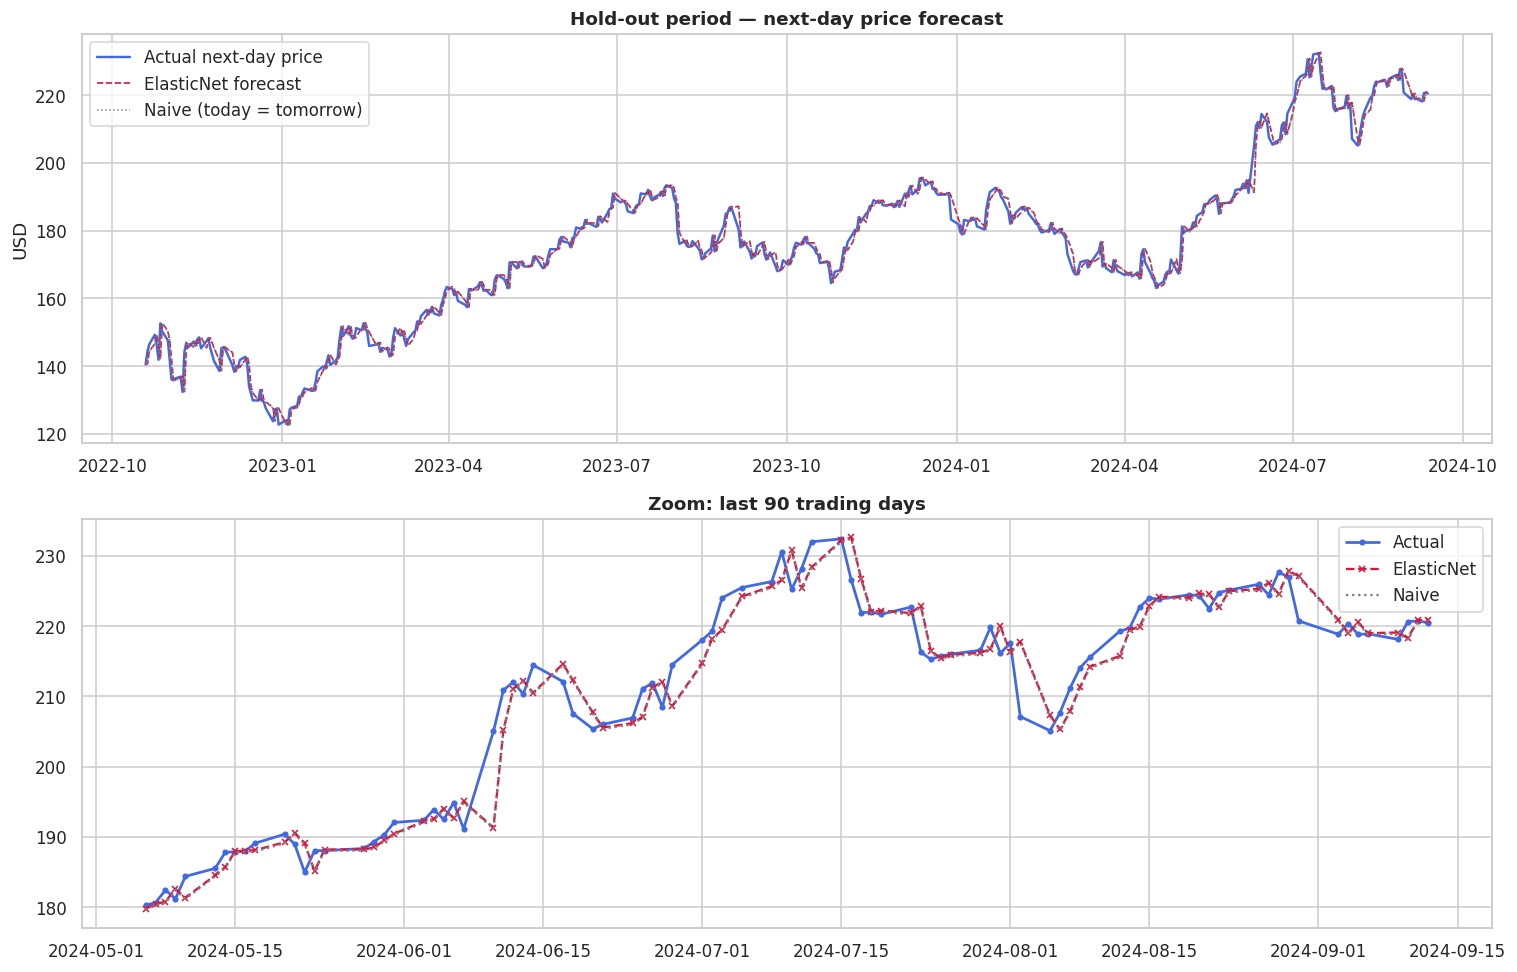

Note: at the price level every model looks excellent because tomorrow's price ~ today's price. The informative comparison is the RETURN error vs the random-walk baseline in the table above.


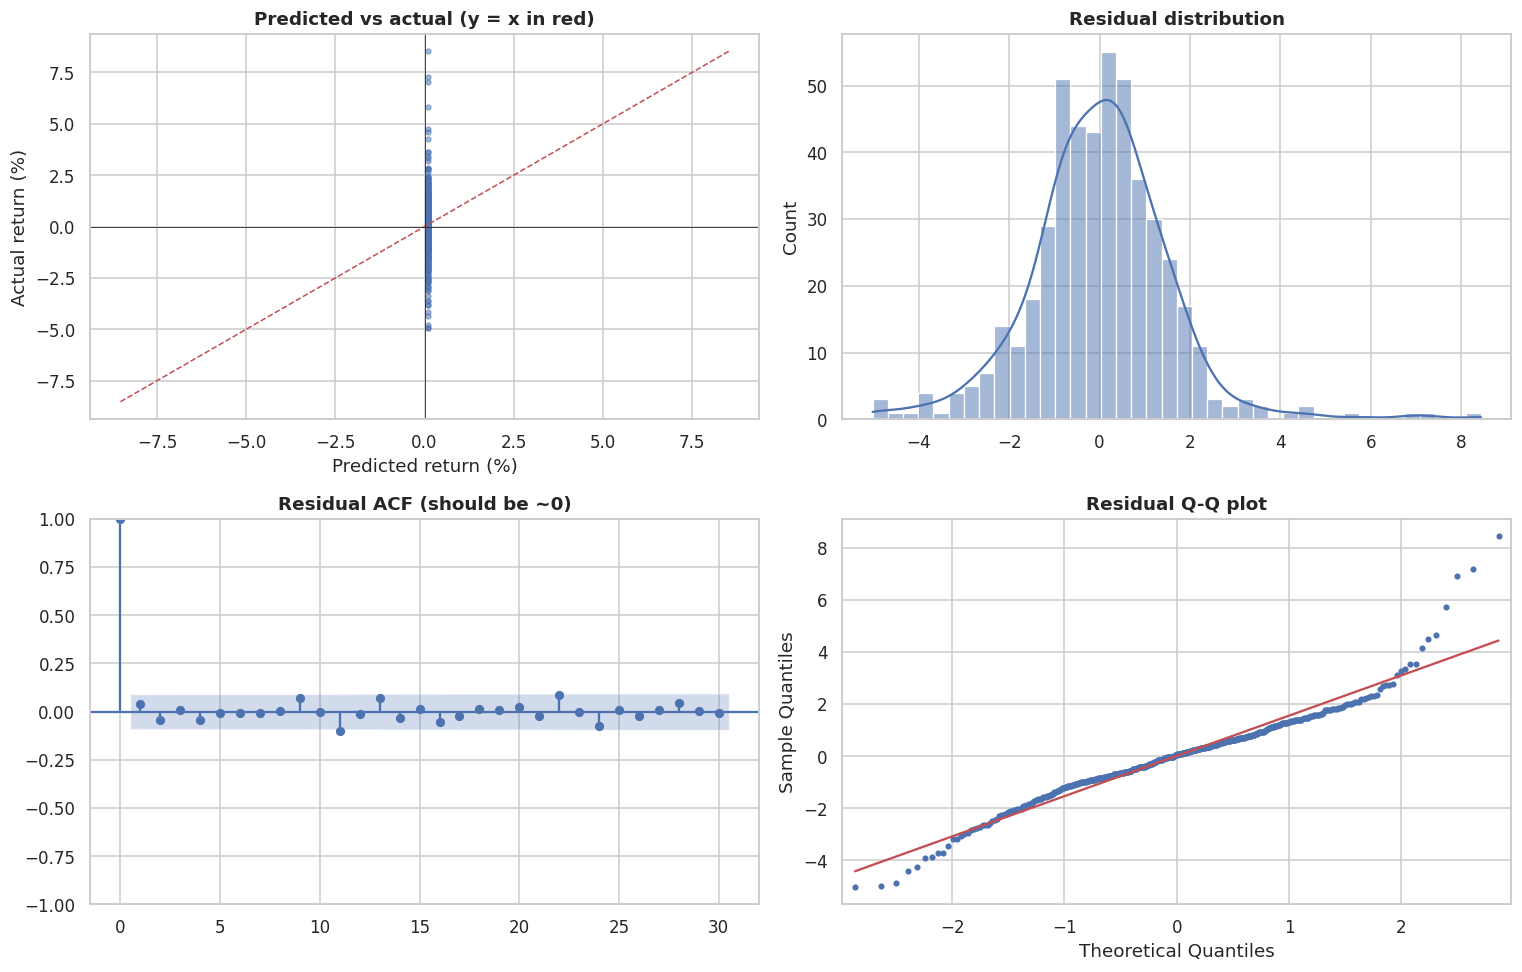

Ljung-Box on residuals (lag 10): p = 0.8803  (no remaining linear structure)


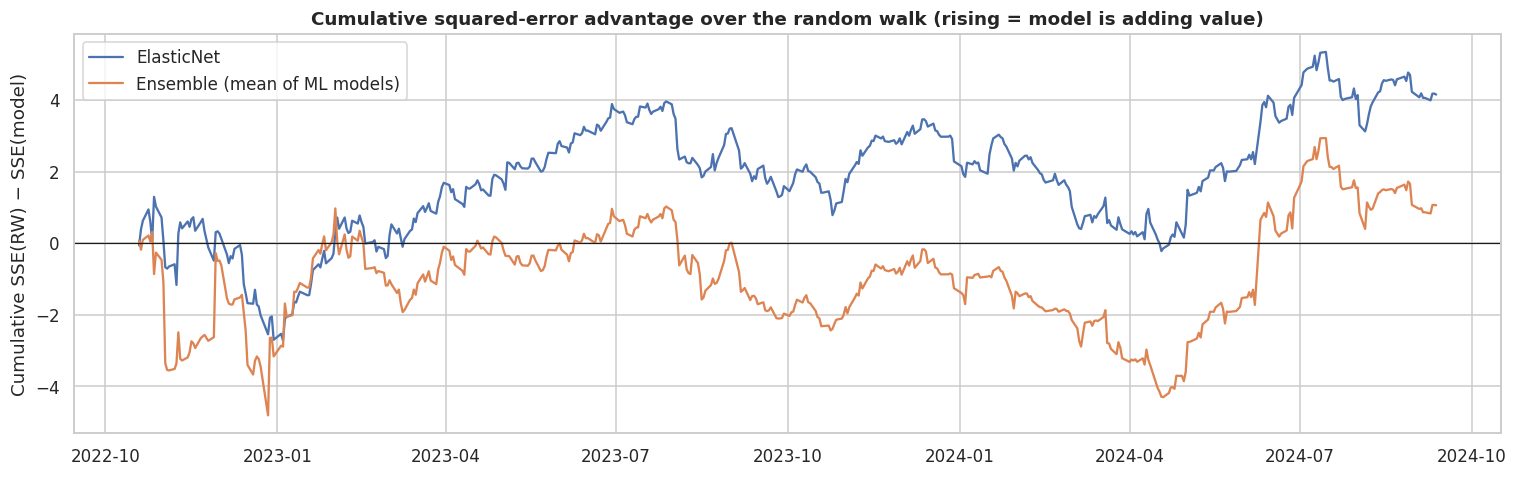

In [19]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9))
idx = test.index
ax[0].plot(idx, P_next, color='royalblue', lw=1.6, label='Actual next-day price')
ax[0].plot(idx, P_t * np.exp(champ_pred / 100), color='crimson', ls='--', lw=1.1, label=f'{champion_name} forecast')
ax[0].plot(idx, P_t, color='gray', ls=':', lw=1, label='Naive (today = tomorrow)')
ax[0].set_title('Hold-out period — next-day price forecast'); ax[0].set_ylabel('USD'); ax[0].legend()
z = 90
ax[1].plot(idx[-z:], P_next[-z:], color='royalblue', lw=1.8, marker='o', ms=3, label='Actual')
ax[1].plot(idx[-z:], (P_t * np.exp(champ_pred / 100))[-z:], color='crimson', ls='--', marker='x', ms=4, label=champion_name)
ax[1].plot(idx[-z:], P_t[-z:], color='gray', ls=':', label='Naive'); ax[1].set_title(f'Zoom: last {z} trading days'); ax[1].legend()
plt.tight_layout(); plt.show()
print('Note: at the price level every model looks excellent because tomorrow\'s price ~ today\'s price. '
      'The informative comparison is the RETURN error vs the random-walk baseline in the table above.')

resid = yt - champ_pred
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
ax[0, 0].scatter(champ_pred, yt, s=10, alpha=0.5); lim = max(np.abs(yt).max(), np.abs(champ_pred).max())
ax[0, 0].plot([-lim, lim], [-lim, lim], 'r--', lw=1); ax[0, 0].axhline(0, color='k', lw=.5); ax[0, 0].axvline(0, color='k', lw=.5)
ax[0, 0].set_xlabel('Predicted return (%)'); ax[0, 0].set_ylabel('Actual return (%)'); ax[0, 0].set_title('Predicted vs actual (y = x in red)')
sns.histplot(resid, kde=True, ax=ax[0, 1], bins=40); ax[0, 1].set_title('Residual distribution')
plot_acf(resid, lags=30, ax=ax[1, 0], title='Residual ACF (should be ~0)')
sm.qqplot(resid, line='s', ax=ax[1, 1], markersize=3); ax[1, 1].set_title('Residual Q-Q plot')
plt.tight_layout(); plt.show()
lb = acorr_ljungbox(resid, lags=[10], return_df=True)
print(f"Ljung-Box on residuals (lag 10): p = {lb['lb_pvalue'].iloc[0]:.4f}  "
      f"({'no' if lb['lb_pvalue'].iloc[0] > 0.05 else 'some'} remaining linear structure)")

plt.figure(figsize=(14, 4.5))
for nm in [champion_name, 'Ensemble (mean of ML models)']:
    plt.plot(idx, np.cumsum(yt ** 2 - (yt - preds[nm]) ** 2), label=nm)
plt.axhline(0, color='k', lw=0.8)
plt.title('Cumulative squared-error advantage over the random walk (rising = model is adding value)')
plt.ylabel('Cumulative SSE(RW) − SSE(model)'); plt.legend(); plt.tight_layout(); plt.show()

### 9.2 Direction classifier on the hold-out set

,Accuracy,Balanced acc.,ROC-AUC,F1
Model,,,,
Always up (majority),0.5409,0.5000,0.5000,0.7020
Logistic Regression,0.4843,0.4642,0.4693,0.5980
Random Forest,0.5136,0.4934,0.4553,0.6221
HistGradientBoosting,0.4927,0.4861,0.4533,0.5468
ElasticNet regressor (sign),0.5409,0.5000,0.5000,0.7020


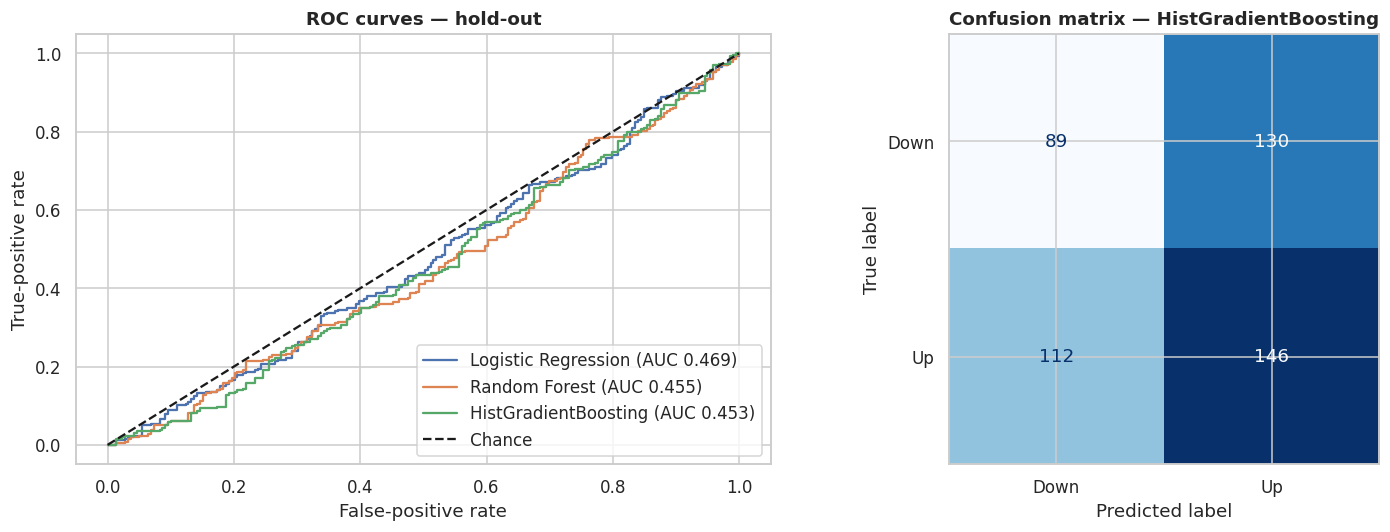

Binomial test: classifier accuracy 0.493 vs majority-class rate 0.541 -> p = 0.9845


In [20]:
proba = {nm: s.best_estimator_.predict_proba(X_test)[:, 1] for nm, s in clf_search.items()}
yd = yd_test.values
base_rate_train = yd_train.mean()
clf_rows = [{'Model': 'Always up (majority)', 'Accuracy': yd.mean(), 'Balanced acc.': 0.5, 'ROC-AUC': 0.5, 'F1': f1_score(yd, np.ones_like(yd))}]
for nm, pr in proba.items():
    yhat = (pr > 0.5).astype(int)
    clf_rows.append({'Model': nm, 'Accuracy': accuracy_score(yd, yhat), 'Balanced acc.': balanced_accuracy_score(yd, yhat),
                     'ROC-AUC': roc_auc_score(yd, pr), 'F1': f1_score(yd, yhat)})
reg_dir = (champ_pred > 0).astype(int)
clf_rows.append({'Model': f'{champion_name} regressor (sign)', 'Accuracy': accuracy_score(yd, reg_dir),
                 'Balanced acc.': balanced_accuracy_score(yd, reg_dir), 'ROC-AUC': roc_auc_score(yd, champ_pred), 'F1': f1_score(yd, reg_dir)})
clf_tbl = pd.DataFrame(clf_rows).set_index('Model')
display(clf_tbl.style.format('{:.4f}').background_gradient(cmap='Greens', axis=0))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for nm, pr in proba.items():
    fpr, tpr, _ = roc_curve(yd, pr); ax[0].plot(fpr, tpr, label=f'{nm} (AUC {roc_auc_score(yd, pr):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', label='Chance'); ax[0].set_xlabel('False-positive rate'); ax[0].set_ylabel('True-positive rate')
ax[0].set_title('ROC curves — hold-out'); ax[0].legend(loc='lower right')
ConfusionMatrixDisplay(confusion_matrix(yd, (proba[clf_champion_name] > 0.5).astype(int)),
                       display_labels=['Down', 'Up']).plot(ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title(f'Confusion matrix — {clf_champion_name}')
plt.tight_layout(); plt.show()

k_c = int(np.sum((proba[clf_champion_name] > 0.5).astype(int) == yd))
clf_binom = stats.binomtest(k_c, len(yd), max(yd.mean(), 1 - yd.mean()), alternative='greater')
print(f'Binomial test: classifier accuracy {k_c / len(yd):.3f} vs majority-class rate {max(yd.mean(), 1 - yd.mean()):.3f} -> p = {clf_binom.pvalue:.4f}')

## 10. Explainability. What drives the model?
Permutation importance measures how much the hold-out error **increases** when a feature's values are shuffled, which is model-agnostic and respects feature interactions. Partial-dependence plots then show the average marginal effect of the top features.

Note: ElasticNet produced (near-)constant forecasts, so feature importance is shown for Ridge instead.


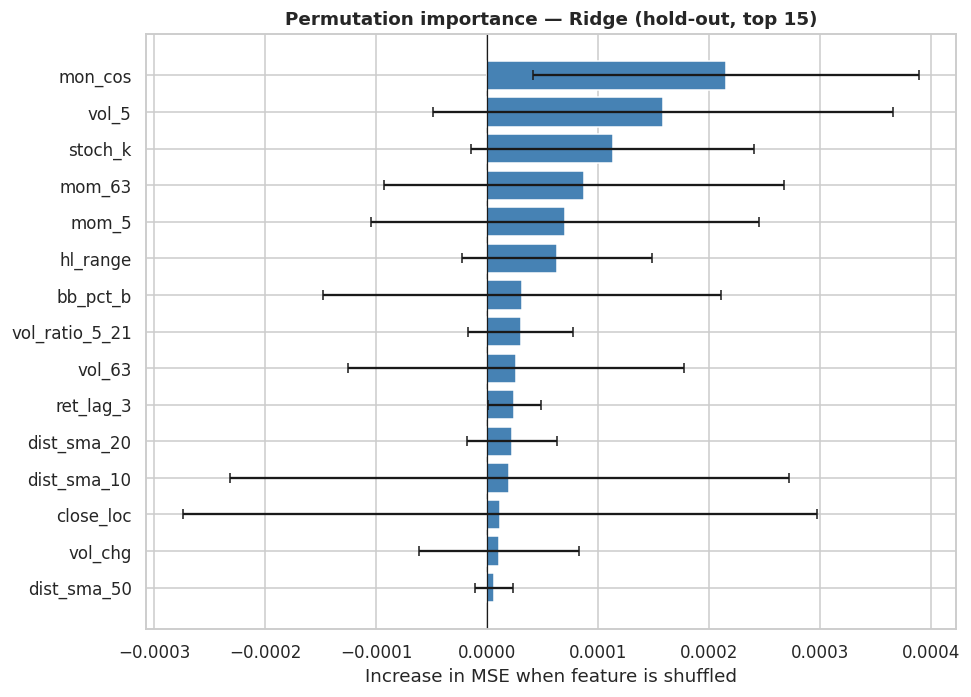

Features with importance <= 0 (or within noise) add nothing out-of-sample — expected when the signal is weak.


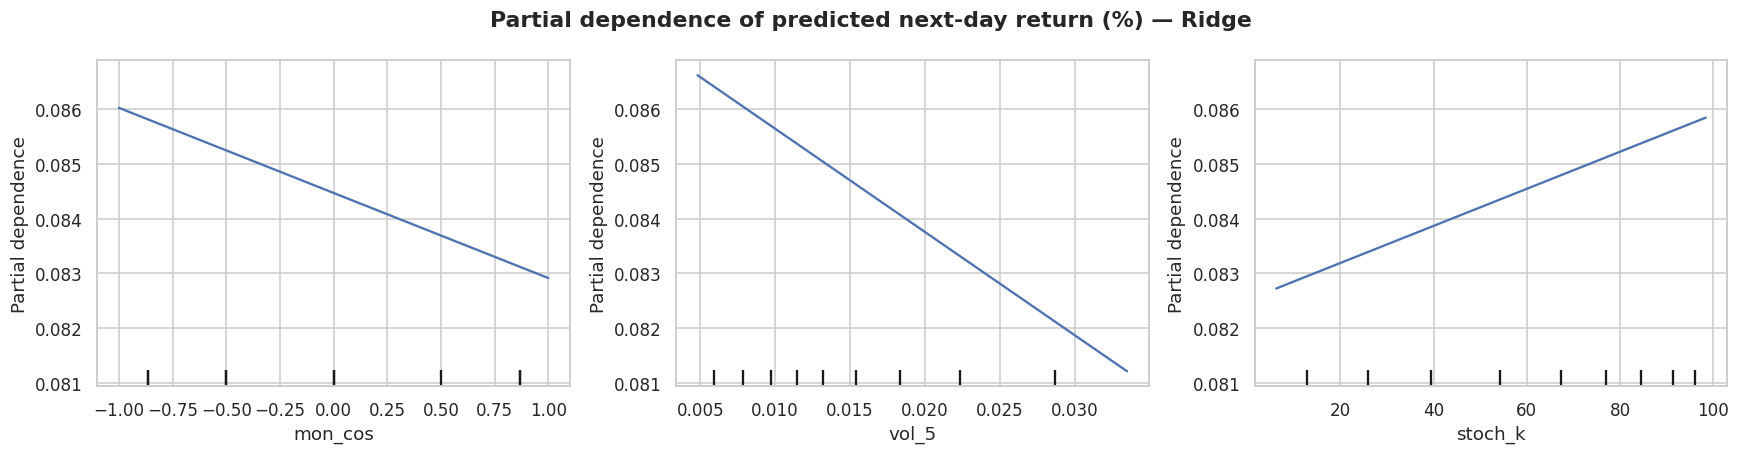


Largest standardised coefficients:


,coef
ret_1,-0.0044
dist_sma_5,-0.0036
gap,-0.0036
intraday,-0.0026
close_loc,-0.0026
bb_pct_b,0.0013
vol_63,0.0015
ret_lag_20,0.0019
is_month_end,0.0023
dow_cos,0.0037


In [21]:
# Heavily-regularised linear models can collapse to a constant forecast on noisy data; in that case
# explain the best-CV model that still produces varying forecasts, so the importance analysis is informative.
varies = {nm: np.std(preds[nm]) > 1e-3 for nm in ml_names}
explain_name = champion_name if varies[champion_name] else max([nm for nm in ml_names if varies[nm]],
                                                                key=lambda k: reg_search[k].best_score_, default=champion_name)
if explain_name != champion_name:
    print(f'Note: {champion_name} produced (near-)constant forecasts, so feature importance is shown for {explain_name} instead.')
explain_est = reg_search[explain_name].best_estimator_

pi = permutation_importance(explain_est, X_test, y_test, scoring='neg_mean_squared_error', n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({'importance': pi.importances_mean, 'std': pi.importances_std}, index=feature_cols).sort_values('importance')
top = imp.tail(15)
plt.figure(figsize=(9, 6.5))
plt.barh(top.index, top['importance'], xerr=top['std'], color='steelblue', capsize=3)
plt.axvline(0, color='k', lw=0.8); plt.xlabel('Increase in MSE when feature is shuffled')
plt.title(f'Permutation importance — {explain_name} (hold-out, top 15)'); plt.tight_layout(); plt.show()
print('Features with importance <= 0 (or within noise) add nothing out-of-sample — expected when the signal is weak.')

top3 = list(imp.index[-3:][::-1])
try:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    PartialDependenceDisplay.from_estimator(explain_est, X_train.astype(float), top3, ax=ax, kind='average')
    fig.suptitle(f'Partial dependence of predicted next-day return (%) — {explain_name}', fontweight='bold'); plt.tight_layout(); plt.show()
except Exception as e:
    print('Partial dependence skipped:', e)

if hasattr(explain_est.named_steps['model'], 'coef_'):
    coefs = pd.Series(explain_est.named_steps['model'].coef_, index=feature_cols).sort_values()
    print('\nLargest standardised coefficients:'); display(pd.concat([coefs.head(5), coefs.tail(5)]).round(4).to_frame('coef'))

## 11. Economic evaluation. Does the signal survive trading costs?
A deliberately simple long/cash strategy: at the close of day *t*, hold the stock for day *t+1* if the model forecasts a positive return (or an up-probability > 50%), otherwise sit in cash (0% return). A one-way cost of `COST_BPS` is charged on every position change. The benchmark is buy-and-hold. Because the position is decided with day-*t* information and earns the day-*t+1* return, there is no look-ahead.

,Total return (%),Ann. return (%),Ann. volatility (%),Sharpe (rf=0),Max drawdown (%),Time invested (%),Position changes
Buy & hold,56.38,26.64,24.71,1.08,-19.59,100.00,0.00
ElasticNet regressor (cost-adj.),56.30,26.61,24.71,1.08,-19.59,100.00,0.00
Ensemble regressor (cost-adj.),38.28,18.68,22.92,0.86,-20.06,92.03,59.00
HistGradientBoosting classifier (cost-adj.),-5.97,-3.20,18.61,-0.08,-24.42,57.86,186.00
"ElasticNet regressor (gross, no costs)",56.38,26.64,24.71,1.08,-19.59,100.00,0.00


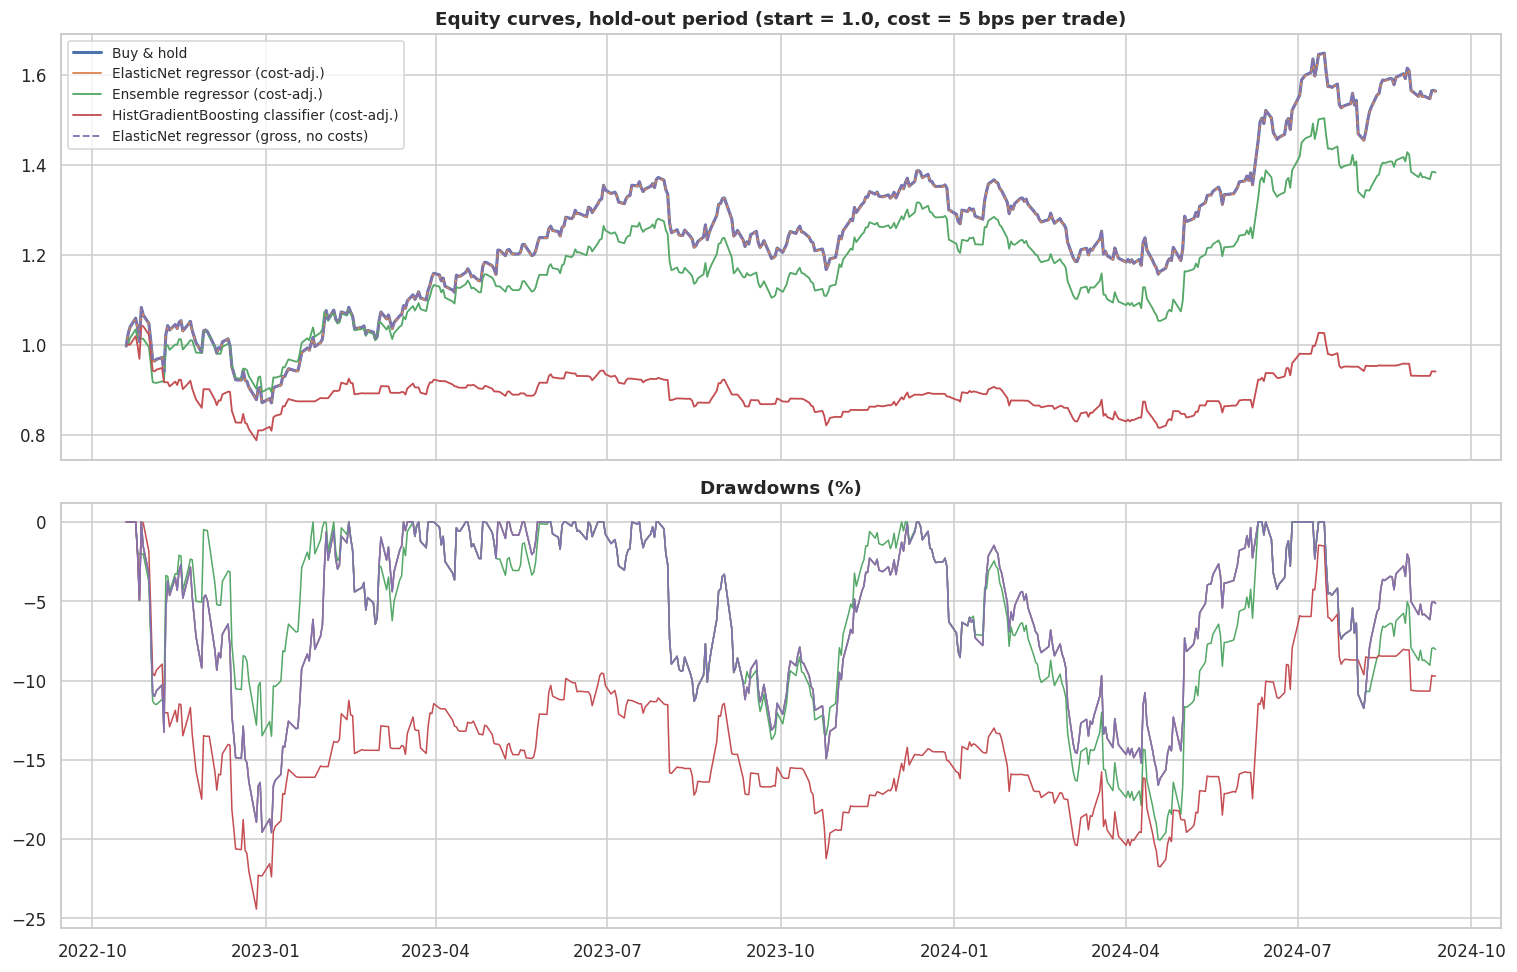

In [22]:
fwd = np.exp(test['target_ret'].values / 100) - 1          # simple return earned on day t+1

def run_backtest(signal, cost_bps):
    pos = pd.Series(np.asarray(signal, dtype=float), index=test.index)
    turnover = pos.diff().abs().fillna(pos.iloc[0])
    return pos * fwd - turnover * cost_bps / 1e4, pos

def perf(ret, pos=None):
    ret = pd.Series(ret); eq = (1 + ret).cumprod(); years = len(ret) / CFG['ANN']
    ann_ret = eq.iloc[-1] ** (1 / years) - 1; ann_vol = ret.std() * np.sqrt(CFG['ANN'])
    out = {'Total return (%)': (eq.iloc[-1] - 1) * 100, 'Ann. return (%)': ann_ret * 100, 'Ann. volatility (%)': ann_vol * 100,
           'Sharpe (rf=0)': ret.mean() / ret.std() * np.sqrt(CFG['ANN']) if ret.std() > 0 else np.nan,
           'Max drawdown (%)': (eq / eq.cummax() - 1).min() * 100}
    if pos is not None:
        out.update({'Time invested (%)': pos.mean() * 100, 'Position changes': int(pos.diff().abs().sum())})
    return out

signals = {
    'Buy & hold': np.ones(len(test)),
    f'{champion_name} regressor (cost-adj.)': (champ_pred > 0),
    'Ensemble regressor (cost-adj.)': (preds['Ensemble (mean of ML models)'] > 0),
    f'{clf_champion_name} classifier (cost-adj.)': (proba[clf_champion_name] > 0.5),
}
curves, bt_rows = {}, {}
for nm, sig in signals.items():
    ret, pos = run_backtest(sig, 0 if nm == 'Buy & hold' else CFG['COST_BPS'])
    curves[nm] = ret; bt_rows[nm] = perf(ret, pos)
gross_nm = f'{champion_name} regressor (gross, no costs)'
ret_g, pos_g = run_backtest(champ_pred > 0, 0); curves[gross_nm] = ret_g; bt_rows[gross_nm] = perf(ret_g, pos_g)
bt_tbl = pd.DataFrame(bt_rows).T
display(bt_tbl.style.format('{:.2f}'))

fig, ax = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for nm, ret in curves.items():
    eq = (1 + ret).cumprod(); ax[0].plot(eq, label=nm, lw=2 if nm == 'Buy & hold' else 1.2, ls='--' if 'gross' in nm else '-')
    ax[1].plot((eq / eq.cummax() - 1) * 100, lw=1)
ax[0].set_title(f'Equity curves, hold-out period (start = 1.0, cost = {CFG["COST_BPS"]} bps per trade)'); ax[0].legend(fontsize=9)
ax[1].set_title('Drawdowns (%)'); plt.tight_layout(); plt.show()

## 12. Robustness — when does the model work (or fail)?
Performance is split by **year** and by **volatility regime** (terciles defined on the *training* data), and a rolling directional-accuracy curve shows how stable any edge is over time.

By year:


,Days,RMSE model,RMSE random walk,Model / RW RMSE,DirAcc
year,,,,,
2022,51,2.616,2.606,1.004,0.412
2023,250,1.275,1.283,0.994,0.560
2024,176,1.480,1.484,0.998,0.551


By volatility regime (ratio < 1 means the model beats the random walk):


,Days,RMSE model,RMSE random walk,Model / RW RMSE,DirAcc
regime,,,,,
Low vol,181,1.342,1.342,1.000,0.470
Mid vol,204,1.382,1.388,0.996,0.598
High vol,92,2.151,2.154,0.999,0.554


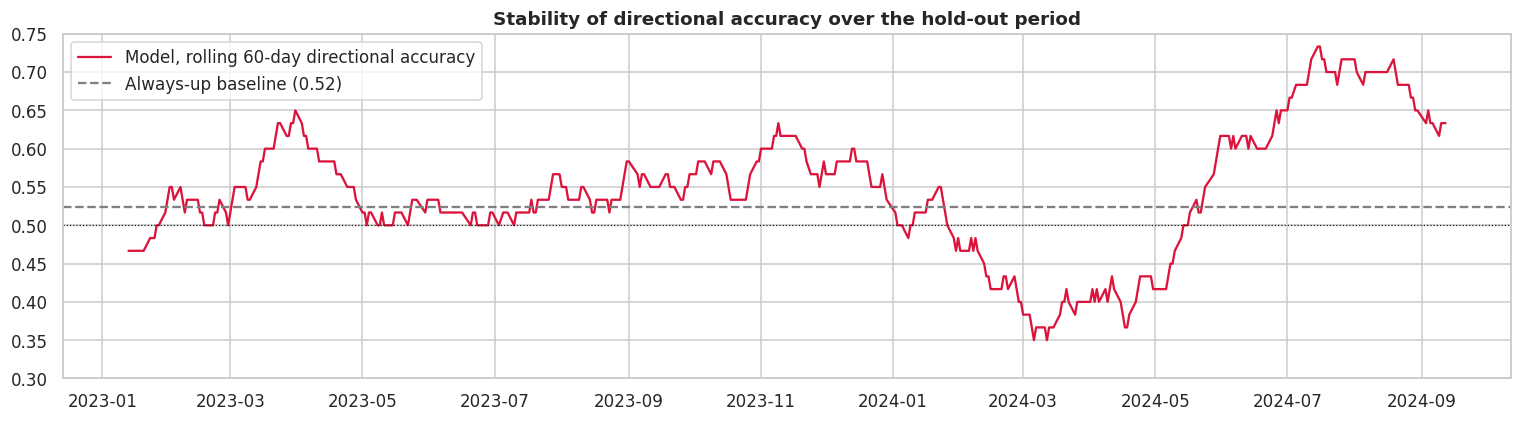

In [23]:
res = pd.DataFrame({'y': yt, 'p': champ_pred}, index=test.index)
res['year'] = res.index.year
vol_thr = X_train['vol_21'].quantile([1 / 3, 2 / 3]).values
res['regime'] = pd.cut(X_test['vol_21'].values, [-np.inf, *vol_thr, np.inf], labels=['Low vol', 'Mid vol', 'High vol'])

def seg_table(by):
    out = res.groupby(by).apply(lambda g: pd.Series({
        'Days': len(g), 'RMSE model': np.sqrt(np.mean((g.y - g.p) ** 2)), 'RMSE random walk': np.sqrt(np.mean(g.y ** 2)),
        'Model / RW RMSE': np.sqrt(np.mean((g.y - g.p) ** 2)) / np.sqrt(np.mean(g.y ** 2)), 'DirAcc': np.mean((g.p > 0) == (g.y > 0))}))
    return out
print('By year:'); display(seg_table('year').style.format({'Days': '{:.0f}', 'RMSE model': '{:.3f}', 'RMSE random walk': '{:.3f}',
                                                           'Model / RW RMSE': '{:.3f}', 'DirAcc': '{:.3f}'}))
print('By volatility regime (ratio < 1 means the model beats the random walk):')
display(seg_table('regime').style.format({'Days': '{:.0f}', 'RMSE model': '{:.3f}', 'RMSE random walk': '{:.3f}',
                                          'Model / RW RMSE': '{:.3f}', 'DirAcc': '{:.3f}'}))

hit = pd.Series((res.p > 0) == (res.y > 0), index=res.index).astype(float)
plt.figure(figsize=(14, 4))
plt.plot(hit.rolling(60).mean(), color='crimson', label='Model, rolling 60-day directional accuracy')
plt.axhline(base_rate_train, color='gray', ls='--', label=f'Always-up baseline ({base_rate_train:.2f})'); plt.axhline(0.5, color='k', ls=':', lw=0.8)
plt.ylim(0.3, 0.75); plt.title('Stability of directional accuracy over the hold-out period'); plt.legend(); plt.tight_layout(); plt.show()

## 13. Deployment artifacts & inference
The champion regressor and classifier are saved together with their feature list and metadata. `predict_next_day()` turns the newest available bar into a forecast for the next trading day.

In [24]:
joblib.dump(reg_search[champion_name].best_estimator_, 'artifacts/best_regression_model.joblib')
joblib.dump(clf_search[clf_champion_name].best_estimator_, 'artifacts/best_direction_model.joblib')
meta = {'ticker': CFG['TICKER'], 'trained_through': str(train.index.max().date()), 'feature_columns': feature_cols,
        'target': 'next-day log return in percent', 'regressor': champion_name, 'classifier': clf_champion_name,
        'holdout_metrics': holdout_tbl.loc[champion_name, ['RMSE', 'MAE', 'R2_OS', 'DirAcc']].to_dict(), 'config': CFG}
with open('artifacts/model_metadata.json', 'w') as fh:
    json.dump(meta, fh, indent=2, default=float)

def predict_next_day(features_row, reg_model, clf_model, last_price):
    r_hat = float(reg_model.predict(features_row[feature_cols])[0])
    p_up = float(clf_model.predict_proba(features_row[feature_cols])[0, 1])
    return {'as_of': str(features_row.index[0].date()), 'last_price': round(float(last_price), 2),
            'predicted_return_%': round(r_hat, 3), 'implied_next_price': round(float(last_price) * np.exp(r_hat / 100), 2),
            'probability_up': round(p_up, 3)}

reg_model = joblib.load('artifacts/best_regression_model.joblib')
clf_model = joblib.load('artifacts/best_direction_model.joblib')
print('Saved:', os.listdir('artifacts'))
print('Latest forecast ->', predict_next_day(live_row, reg_model, clf_model, df['Close'].loc[live_row.index[0]]))
print('(Illustrative only — not financial advice.)')

Saved: ['model_metadata.json', 'best_regression_model.joblib', 'best_direction_model.joblib']
Latest forecast -> {'as_of': '2024-09-13', 'last_price': 220.49, 'predicted_return_%': 0.085, 'implied_next_price': np.float64(220.67), 'probability_up': 0.481}
(Illustrative only — not financial advice.)


## 14. Conclusions
The cell below writes the headline findings **directly from the results computed above**, so the text always matches the numbers after a re-run.

In [25]:
best_h = holdout_tbl.drop(index=['Random walk (0%)', 'Historical mean']).iloc[0]
best_h_name = holdout_tbl.drop(index=['Random walk (0%)', 'Historical mean']).index[0]
dm_champ = dm_rows[0]
bh, strat = bt_tbl.loc['Buy & hold'], bt_tbl.loc[f'{champion_name} regressor (cost-adj.)']

print('=' * 88)
print('PROJECT CONCLUSIONS (auto-generated from this run)')
print('=' * 88)
print(f"RQ1  Data: AAPL returns are fat-tailed (excess kurtosis {stats.kurtosis(r):.1f}), stationary, almost serially uncorrelated\n"
      f"     (lag-1 rho = {findings['corr(ret_t, ret_t+1)  [return autocorrelation]']:+.3f}) but show strong volatility clustering "
      f"(|ret| rho = {findings['corr(|ret_t|, |ret_t+1|)  [volatility persistence]']:+.3f}).")
print(f"\nRQ2  Regression: best hold-out model = {best_h_name} (RMSE {best_h['RMSE']:.4f}% vs random-walk {holdout_tbl.loc['Random walk (0%)', 'RMSE']:.4f}%, "
      f"R2_OS = {best_h['R2_OS']:+.4f}).")
print(f"     The pre-selected champion ({champion_name}) has DM p = {dm_champ['DM p-value (two-sided)']:.3f} -> "
      f"{'a statistically significant' if (dm_champ['DM p-value (two-sided)'] < 0.05 and dm_champ['DM stat vs random walk'] > 0) else 'NO statistically significant'} "
      f"improvement over predicting 0%.")
print(f"     Directional accuracy {dm_champ['Directional accuracy']:.3f} vs always-up {dm_champ['Always-up accuracy (test)']:.3f} "
      f"(binomial p = {dm_champ['Binomial p (acc > base rate)']:.3f}).")
print(f"     Classifier ROC-AUC on hold-out = {clf_tbl.loc[clf_champion_name, 'ROC-AUC']:.3f} (0.5 = chance).")
print(f"\nRQ3  Economics: strategy Sharpe {strat['Sharpe (rf=0)']:.2f} vs buy-and-hold {bh['Sharpe (rf=0)']:.2f}; "
      f"total return {strat['Total return (%)']:.1f}% vs {bh['Total return (%)']:.1f}%; max drawdown {strat['Max drawdown (%)']:.1f}% vs {bh['Max drawdown (%)']:.1f}% "
      f"(after {CFG['COST_BPS']} bps costs).")
degenerate = np.std(champ_pred) < 1e-3
verdict_sig = (not degenerate) and ((dm_champ['DM p-value (two-sided)'] < 0.05 and dm_champ['DM stat vs random walk'] > 0)
                                    or (dm_champ['Binomial p (acc > base rate)'] < 0.05))
if degenerate:
    print('\nNOTE: the champion\'s forecasts are (almost) constant — the regularisation shrank every coefficient to ~0 because the features carry\n'
          '      no usable signal for the next-day return. Its "directional accuracy" is just the always-up rate and must not be read as skill.')
print('\nVERDICT: ' + ('There is statistical evidence of out-of-sample predictability in this run — validate it on other periods/tickers before trusting it.'
      if verdict_sig else
      'No reliable out-of-sample edge over naive benchmarks. This is the expected result for a liquid mega-cap stock and is consistent with market efficiency.'))

PROJECT CONCLUSIONS (auto-generated from this run)
RQ1  Data: AAPL returns are fat-tailed (excess kurtosis 5.4), stationary, almost serially uncorrelated
     (lag-1 rho = -0.010) but show strong volatility clustering (|ret| rho = +0.127).

RQ2  Regression: best hold-out model = Random Forest (RMSE 1.5456% vs random-walk 1.5495%, R2_OS = +0.0050).
     The pre-selected champion (ElasticNet) has DM p = 0.468 -> NO statistically significant improvement over predicting 0%.
     Directional accuracy 0.541 vs always-up 0.541 (binomial p = 0.519).
     Classifier ROC-AUC on hold-out = 0.453 (0.5 = chance).

RQ3  Economics: strategy Sharpe 1.08 vs buy-and-hold 1.08; total return 56.3% vs 56.4%; max drawdown -19.6% vs -19.6% (after 5 bps costs).

NOTE: the champion's forecasts are (almost) constant — the regularisation shrank every coefficient to ~0 because the features carry
      no usable signal for the next-day return. Its "directional accuracy" is just the always-up rate and must not be r

### Limitations
* **Single asset, single regime.** AAPL in 2015–2024 was a historically strong bull market; "always up" is a tough benchmark and results may not transfer to other stocks or periods.
* **Only price/volume information.** No fundamentals, macro, options, news or sentiment data.
* **Simplified trading model.** Long/cash only, no slippage, taxes, borrow costs or position sizing; costs are a flat basis-point assumption.
* **Statistical power.** A hold-out of ~480 days cannot reliably detect the tiny edges (a few tenths of a percent of R²) that exist in daily returns — hence the significance tests.
* **Multiple testing.** Several models, features and metrics were compared; any single "significant" result should be treated with caution.

### Recommended next steps
1. **Forecast volatility instead of direction** EDA showed strong volatility clustering; GARCH / HAR-RV / gradient boosting on realised-volatility features usually yields genuinely predictive models and directly supports risk management and position sizing.
2. Add **exogenous data**: VIX, S&P 500 / Nasdaq returns, interest rates, sector ETFs, earnings-date flags, news sentiment.
3. Move to **multi-asset / panel models** (many tickers share one model) to increase sample size.
4. Try **sequence models** (LSTM / Temporal Fusion Transformer) and **quantile regression** to forecast return distributions rather than point estimates.
5. Evaluate with **rolling-origin re-training** (re-fit every month) and add a probability-threshold / confidence-based trading rule.
6. Wrap `predict_next_day()` in a small **Streamlit/FastAPI app** and monitor live forecast error for drift.